<img src="https://images.seeklogo.com/logo-png/28/1/u-cayetano-heredia-logo-png_seeklogo-289967.png"
     alt="LOGO UPCH" width="250" align="right">

<br>

<h1><font color="#7F000E" size="5">UNIVERSIDAD PERUANA CAYETANO HEREDIA</font></h1>

<h1><font color="#7F000E" size="6">SEÑALES BIOMÉDICAS</font></h1>

<h1><font color="#7F000E" size="4">LABORATORIO 10 — Extracción de características de sEMG con nuestros registros</font></h1>

<br>

<div style="text-align:right">
  <font color="#7F000E" size="3">Docente: Ing. Alexander Valdez Portocarrero</font><br>
  <font color="#7F000E" size="3">Curso: Introducción a las Señales Biomédicas</font><br>
  <font color="#7F000E" size="3">Integrantes: Zaida Sofia Pinco Quispe, Adriana Tayli Abanto Trujillo, Kimberly Cristel Soto Concha, Antonella Chiara Zelvaggio Napa, Daniel Jesus Navarro Lopez</font><br>
  <font color="#7F000E" size="3">Registros: reposoSujeto1 y Movimiento_contrafuerza_Adriana (BITalino, canal A2, 04/09/2026)</font><br>
</div>

## Cómo leer este cuaderno

Este cuaderno sigue la misma estructura del laboratorio de referencia, pero **todo está calculado con nuestros propios registros**. Después de cada resultado importante hay tres tipos de celdas:

| Marca | Qué contiene |
|---|---|
| 📘 **Explicación** | Qué hizo la celda anterior y cómo leer su resultado |
| ✅ **Respuesta** | Respuesta a las preguntas de verificación y a los ejercicios |
| 🔎 **Verificación adicional** | Cálculos extra para sustentar una respuesta con números |

**Regla:** toda cifra de las explicaciones sale de una salida de código visible en este cuaderno. Cuando una respuesta es **conceptual** (depende de la teoría y no de nuestros datos), se indica.

### Nuestro protocolo
- **Sujeto:** Adriana. **Sensor:** EMG BITalino (r)evolution, **canal A2**, electrodos sobre el brazo.
- **Baseline (`reposoSujeto1`):** 62 s con el brazo relajado sobre la mesa, grabado a las 14:56.
- **Prueba (`Movimiento_contrafuerza_Adriana`):** 239 s grabados a las 15:02. Contiene **3 contracciones sostenidas contra resistencia** (de ~12 a ~17 s cada una), separadas por reposos largos.


### Resumen de resultados clave

| Aspecto | Resultado obtenido |
|---|---|
| Frecuencia de muestreo / resolución | 1000 Hz / 10 bits |
| Duración de los registros | BASELINE 62.2 s · PRUEBA 239.2 s |
| Rango medible del sensor | ±1.632 mV (1 cuenta ADC = 3.19 µV) |
| Saturación | **0 muestras** (pico de 1.223 mV, 75 % del rango) |
| Piso de ruido (RMS del baseline filtrado) | 5.30 µV |
| SNR aproximada (registro completo) | 20.7 dB |
| Contracciones detectadas | 3 sostenidas, de 14.15 ± 2.18 s |
| Ventanas de 250 ms | 1913 (1524 reposo · 336 contracción · 53 transición) |
| Característica más discriminante (Fisher) | **MNF (14.68)**, seguida de P_150_450 (14.52) y MDF (8.58) |
| LDA / SVM con todas las características | 0.955 / 0.973 |
| Un solo umbral en RMS | 0.982 |
| CNN con espectrogramas | 0.976 ± 0.015 |
| ¿Evidencia de fatiga? | No concluyente: dentro de cada contracción cae el esfuerzo (RMS ↓) y la MDF sube |

**Montaje de adquisición** (BITalino con sensor EMG en el brazo, registro en OpenSignals):

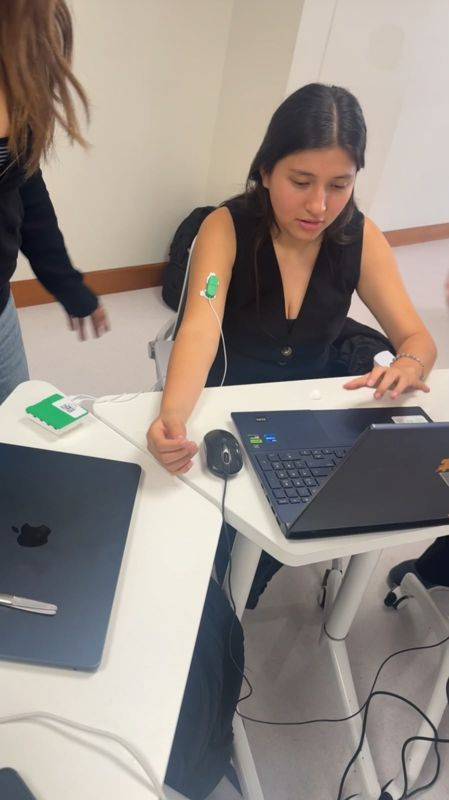

## Pregunta guía del laboratorio

> **¿Cómo convierte un dispositivo la actividad eléctrica de un músculo en números que puede entender?**

Una prótesis mioeléctrica, un exoesqueleto de rehabilitación o un sistema que detecta fatiga en un trabajador **no "miran" la señal cruda**: la resumen en un conjunto pequeño de números llamados **características** (*features*). Elegir y calcular bien esas características es, muchas veces, más importante que el clasificador que viene después.

### Objetivos de aprendizaje
Al terminar este laboratorio podrás:

1. Explicar el **origen fisiológico** de la sEMG y sus rangos típicos de amplitud y frecuencia.
2. **Convertir, filtrar y evaluar la calidad** de una señal real adquirida con BITalino.
3. **Segmentar** la señal en ventanas y **etiquetar** automáticamente reposo y contracción.
4. Calcular e interpretar características **temporales, estadísticas y espectrales**.
5. Construir una **matriz de características** y entrenar un clasificador **sin fuga de datos**.
6. Entender cómo una **CNN** aprende características a partir del **espectrograma (STFT)** y compararla con el enfoque clásico.

### Agenda (120 min)

| Bloque | Tiempo | Tipo |
|---|---|---|
| 0. Introducción y configuración | 5 min | Motivación |
| 1. Fundamentos fisiológicos | 15 min | Teoría + simulación |
| 2. Instrumentación y adquisición | 10 min | Técnica + práctica |
| 3. Preprocesamiento | 15 min | Práctica |
| 4. Segmentación y etiquetado | 10 min | Técnica + práctica |
| 5. Extracción de características clásicas | 25 min | Teoría + práctica |
| 6. Del vector de características al clasificador | 15 min | Práctica |
| 7. Deep learning: espectrograma + CNN | 15 min | Teoría + demo |
| 8. Ejercicios, cierre y referencias | 10 min | Síntesis |

**Datos del laboratorio (nuestros):** dos registros del brazo tomados con BITalino:
- `reposoSujeto1-09-04_14-56-07.txt` — músculo en **reposo** (referencia de ruido).
- `Movimiento_contrafuerza_Adriana-09-04_15-02-01.txt` — **3 contracciones sostenidas contra resistencia** separadas por reposo.

## 0. Configuración del entorno

Todas las bibliotecas usadas vienen preinstaladas en Google Colab (`numpy`, `scipy`, `pandas`, `matplotlib`, `scikit-learn`, `torch`). No es necesario `opensignalsreader`: escribiremos nuestro propio lector para **entender** el formato del archivo.

In [34]:
import os, sys, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy import signal
from scipy.stats import kurtosis, skew

warnings.filterwarnings("ignore", category=RuntimeWarning)
np.random.seed(42)

plt.rcParams.update({
    "figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
    "axes.spines.top": False, "axes.spines.right": False,
})
COLOR_REPOSO, COLOR_CONTRAC, COLOR_UPCH = "#4C72B0", "#C44E52", "#7F000E"

try:
    from IPython.display import display
except ImportError:
    display = print

print("Entorno listo.")

Entorno listo.


📘 **Explicación.** Esta celda solo prepara el entorno: importa las bibliotecas, fija una semilla aleatoria (`np.random.seed(42)`) para que la simulación salga igual cada vez y define los colores de las gráficas. El mensaje *"Entorno listo."* confirma que todo se cargó sin errores.

---
# 1. Fundamentos fisiológicos (15 min)

### 1.1 La unidad motora
El músculo no se contrae "en bloque". Se organiza en **unidades motoras (UM)**: una **motoneurona** de la médula espinal y **todas las fibras musculares que inerva**. Cuando la motoneurona dispara, todas sus fibras se despolarizan casi a la vez y producen un **potencial de acción de unidad motora (MUAP)**: una forma de onda bifásica o trifásica de pocos milisegundos.

El sistema nervioso regula la fuerza con dos mecanismos:

| Mecanismo | Qué ocurre | Efecto en la sEMG |
|---|---|---|
| **Reclutamiento** | Se activan más unidades motoras (primero las pequeñas — *principio de Henneman*) | Aumenta la amplitud |
| **Codificación por frecuencia** | Cada UM dispara más rápido (≈ 8 a 30 disparos/s) | Aumenta amplitud y densidad de la señal |

### 1.2 ¿Qué registra un electrodo de superficie?
Un electrodo sobre la piel no ve una UM aislada: ve la **suma espacial y temporal** de los MUAPs de muchas unidades, filtrada por grasa, piel y la propia distancia. El resultado es un **patrón de interferencia** que parece ruido aleatorio, pero cuya **amplitud** y **contenido espectral** codifican información sobre la activación muscular.

> 💡 **Idea clave:** la sEMG es como escuchar un estadio lleno desde afuera. No entiendes a ninguna persona en particular, pero sí sabes si hay pocos o muchos gritando (amplitud) y si las voces son agudas o graves (frecuencia).

### 1.3 Rangos típicos de la sEMG

| Propiedad | Valor típico |
|---|---|
| Amplitud | 0 – 10 mV pico a pico (en reposo: microvoltios) |
| Banda útil | ≈ 10 / 20 – 450 / 500 Hz |
| Energía dominante | ≈ 50 – 150 Hz |
| Distribución de amplitudes | Aproximadamente gaussiana de media cero en contracción sostenida |

Factores que la modifican: grosor del tejido adiposo, posición y distancia entre electrodos, temperatura, **fatiga** (desplaza el espectro a frecuencias más bajas), impedancia piel-electrodo y artefactos.

Veamos cómo surge el patrón de interferencia con una **simulación** simple.

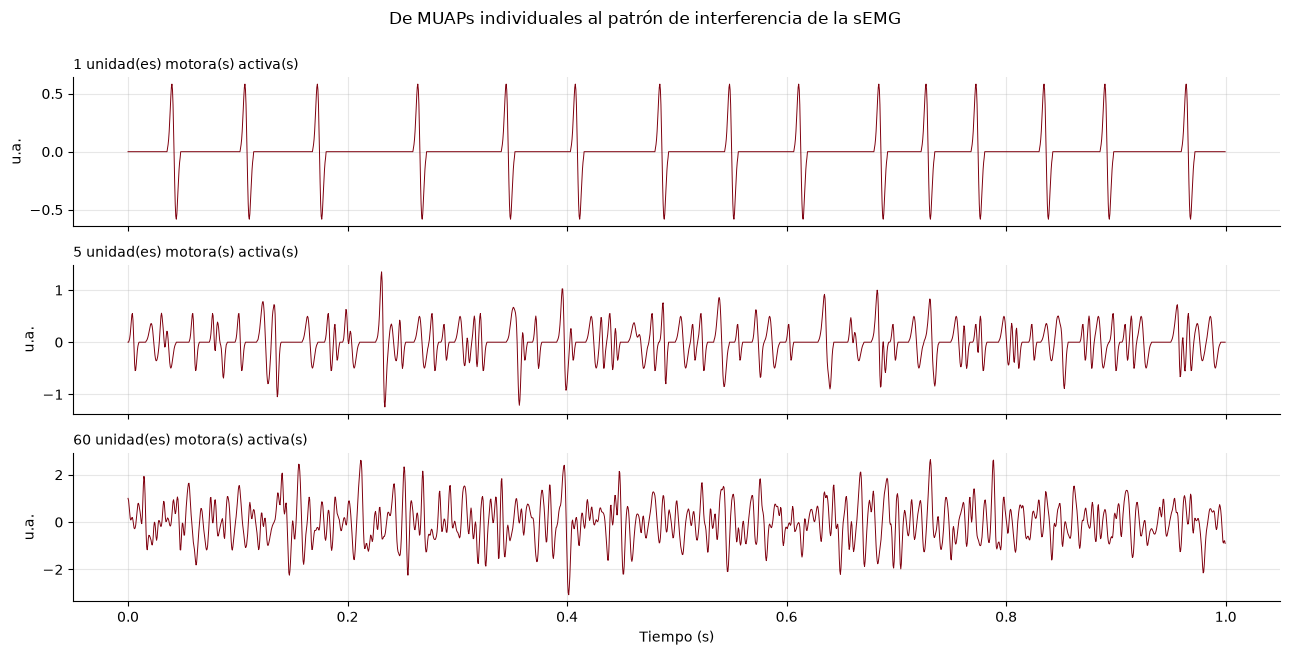

In [35]:
# Simulación didáctica: suma de trenes de MUAPs
FS_SIM = 2000
t_sim = np.arange(0, 1.0, 1/FS_SIM)

def muap(duracion_ms=10, fs=FS_SIM):
    # Forma bifásica tipo "derivada de gaussiana" (modelo simplificado de MUAP)
    tt = np.arange(-duracion_ms/2, duracion_ms/2, 1000/fs) / 1000
    s = duracion_ms / 1000 / 6
    return -tt / s * np.exp(-tt**2 / (2*s**2))

def tren_um(fr_hz, amplitud, dur_ms, fs=FS_SIM, n=len(t_sim)):
    # Una unidad motora disparando a ~fr_hz con variabilidad del 20 % entre disparos
    x = np.zeros(n); k = np.random.uniform(0, 1/fr_hz)
    while k < n/fs:
        x[int(k*fs)] = 1
        k += np.random.normal(1/fr_hz, 0.2/fr_hz)
    return amplitud * np.convolve(x, muap(dur_ms, fs), mode="same")

fig, ax = plt.subplots(3, 1, figsize=(13, 6.5), sharex=True)
for a, n_um in zip(ax, [1, 5, 60]):
    total = sum(tren_um(np.random.uniform(8, 25), np.random.uniform(0.2, 1.0),
                        np.random.uniform(6, 14)) for _ in range(n_um))
    a.plot(t_sim, total, lw=0.7, color=COLOR_UPCH)
    a.set_title(f"{n_um} unidad(es) motora(s) activa(s)", loc="left", fontsize=10)
    a.set_ylabel("u.a.")
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("De MUAPs individuales al patrón de interferencia de la sEMG", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** La simulación construye la sEMG "desde abajo":
1. Se crea la forma de **un** MUAP (una onda que sube y baja en pocos milisegundos).
2. Cada unidad motora "dispara" ese MUAP entre 8 y 25 veces por segundo, con algo de irregularidad.
3. Se **suman** los trenes de 1, 5 y 60 unidades motoras.

En la gráfica de arriba (1 UM) se ven picos separados y regulares, uno por cada disparo. En la del medio (5 UM) los picos empiezan a mezclarse. En la de abajo (60 UM) ya no se distingue ningún disparo: la señal parece ruido. Además, el eje vertical crece de una gráfica a otra: **más unidades activas producen más amplitud**.

> ❓ **Preguntas de verificación**
> 1. Con 1 unidad motora, ¿puedes distinguir cada disparo? ¿Y con 60?
> 2. ¿Qué mecanismo fisiológico representa pasar de 5 a 60 unidades?
> 3. Si la señal con 60 UM "parece ruido", ¿por qué sigue siendo útil? ¿Qué cambia entre las tres gráficas que sí podríamos medir?

✅ **Respuestas**

1. **Con 1 UM, sí:** cada disparo aparece como un pico aislado, separado del siguiente. **Con 60 UM, no:** los MUAPs se superponen en el tiempo y forman un patrón continuo (patrón de interferencia) donde ningún disparo individual es reconocible.
2. Representa el **reclutamiento**: el sistema nervioso activa más unidades motoras para producir más fuerza.
3. Aunque no podamos ver cada disparo, la señal sigue llevando información en **propiedades globales** que sí se pueden medir. La principal es la **amplitud**: en la figura, el rango del eje vertical crece al pasar de 1 a 5 y a 60 UM, y eso lo captura una medida como el RMS. También cambia la **densidad** de la señal (cuántas veces sube y baja por segundo), que capturan medidas como los cruces por cero. Esas propiedades son justamente las **características** que calcularemos en el Bloque 5.

---
# 2. Instrumentación y adquisición (10 min)

### 2.1 Cadena de adquisición del BITalino
```
Músculo → electrodos Ag/AgCl → amplificador diferencial (G = 1009) → filtro analógico → ADC 10 bits → Bluetooth → OpenSignals (.txt)
```

- **Configuración bipolar / diferencial:** dos electrodos sobre el vientre muscular y uno de referencia en zona eléctricamente neutra (hueso). El amplificador **resta** ambos electrodos: lo que es común a los dos (p. ej., interferencia de la red eléctrica) se cancela (*rechazo en modo común*, CMRR).
- **Colocación:** recomendaciones **SENIAM** — electrodos alineados con las fibras, entre el punto motor y el tendón, con ~20 mm entre centros; piel limpia para reducir la impedancia.

### 2.2 Muestreo y cuantización
- **Frecuencia de muestreo:** el archivo indica **Fs = 1000 Hz** → frecuencia de Nyquist = 500 Hz. Cubre la banda útil de la sEMG.
- **Resolución:** 10 bits → el ADC entrega enteros de **0 a 1023**. El valor ~512 corresponde a 0 V.

### 2.3 Conversión de unidades (hoja técnica del sensor EMG BITalino)

$$
\text{EMG}_{mV} = \frac{\left(\dfrac{ADC}{2^{n}} - \dfrac{1}{2}\right)\cdot V_{CC}}{G_{EMG}} \times 1000,
\qquad V_{CC}=3.3\ \text{V},\ G_{EMG}=1009,\ n = 10
$$

Esto da un rango de medición de aproximadamente **±1.64 mV**. Cualquier actividad mayor **satura** el ADC (se queda pegada en 0 o en 1023).

### 2.4 Fuentes de ruido y artefactos

| Fuente | Característica | Cómo se trata |
|---|---|---|
| Red eléctrica | 60 Hz en Perú (y armónicos) | Diferencial + filtro *notch* |
| Movimiento de electrodos/cables | < 20 Hz, gran amplitud | Pasa-altos ≈ 20 Hz, buena fijación |
| ECG (cerca del tórax) | Picos periódicos ~1 Hz | Pasa-altos, ubicación |
| Ruido térmico/electrónico | Banda ancha, bajo nivel | Se estima con un registro en reposo |
| **Saturación (clipping)** | Señal "aplanada" en el máximo/mínimo del ADC | Prevención (ganancia) y detección |

> 💡 **Idea clave:** ningún filtro digital recupera información que se perdió por saturación. La calidad empieza en la adquisición.

### 2.5 Carga de los archivos

El formato de texto de OpenSignals tiene tres partes:
1. Línea `# OpenSignals Text File Format`.
2. Línea `# {...}` con un **JSON** de metadatos: frecuencia de muestreo, resolución, sensores, nombres de columnas.
3. `# EndOfHeader` y luego los datos en columnas separadas por tabulaciones (`nSeq`, entradas digitales, `A2`...).

Escribimos un lector que **lee los metadatos del propio archivo** en lugar de suponerlos. **Importante:** nuestro sensor estaba conectado al canal **A2** (no A1 como en el ejemplo), así que el lector toma el canal desde la cabecera.

**En Colab:** ejecuta la celda siguiente; si los archivos no están en la carpeta, se abrirá un diálogo para subirlos (deben conservar su nombre).

In [36]:
RUTA_BASELINE = "reposoSujeto1-09-04_14-56-07.txt"
RUTA_PRUEBA   = "Movimiento_contrafuerza_Adriana-09-04_15-02-01.txt"

EN_COLAB = "google.colab" in sys.modules
if EN_COLAB and not (os.path.exists(RUTA_BASELINE) and os.path.exists(RUTA_PRUEBA)):
    from google.colab import files
    print(f"Sube {RUTA_BASELINE} y {RUTA_PRUEBA} (puedes seleccionar ambos a la vez).")
    files.upload()

for ruta in [RUTA_BASELINE, RUTA_PRUEBA]:
    if not os.path.exists(ruta):
        raise FileNotFoundError(f"No se encontró {ruta}. Súbelo a la carpeta de trabajo con ese nombre exacto.")
print("Usando señal REAL (BITalino) — registros propios del grupo")

Usando señal REAL (BITalino) — registros propios del grupo


📘 **Explicación.** La celda buscó los dos archivos en la carpeta de trabajo. Como los encontró, el cuaderno trabaja con **nuestra señal real del BITalino**. (Se quitó la señal simulada del ejemplo: si falta un archivo, la celda avisa con un error claro.)

In [37]:
def leer_opensignals(ruta, etiqueta_canal=None):
    # Lee un TXT de OpenSignals y devuelve (valores ADC del canal, diccionario de metadatos).
    # Si no se indica el canal, usa el primero que aparece en "label" (en nuestros registros: A2).
    with open(ruta, "r", encoding="utf-8") as f:
        cabecera = [next(f) for _ in range(3)]
    meta = list(json.loads(cabecera[1].lstrip("# ").strip()).values())[0]
    if etiqueta_canal is None:
        etiqueta_canal = meta["label"][0]
    datos = np.loadtxt(ruta, comments="#")
    idx_col = meta["column"].index(etiqueta_canal)
    meta["bits"] = meta["resolution"][idx_col]
    meta["canal"] = etiqueta_canal
    return datos[:, idx_col].astype(float), meta


adc_base, meta_base = leer_opensignals(RUTA_BASELINE)
adc_prueba, meta_prueba = leer_opensignals(RUTA_PRUEBA)

FS = int(meta_prueba["sampling rate"])
N_BITS = int(meta_prueba["bits"])
assert FS == int(meta_base["sampling rate"]), "Los registros tienen Fs distintas."

for nombre, adc, meta in [("BASELINE", adc_base, meta_base), ("PRUEBA", adc_prueba, meta_prueba)]:
    print(f"{nombre:9s} | canal {meta['canal']} | sensor: {meta['sensor'][0]:9s} | fecha: {meta['date']} {meta['time']} | "
          f"Fs = {meta['sampling rate']} Hz | {meta['bits']} bits | "
          f"{len(adc):,} muestras = {len(adc)/FS:.1f} s | ADC min/max: {adc.min():.0f}/{adc.max():.0f}")

BASELINE  | canal A2 | sensor: EMGBITREV | fecha: 2026-9-4 14:56:19.776 | Fs = 1000 Hz | 10 bits | 62,250 muestras = 62.2 s | ADC min/max: 496/514
PRUEBA    | canal A2 | sensor: EMGBITREV | fecha: 2026-9-4 15:2:5.788 | Fs = 1000 Hz | 10 bits | 239,250 muestras = 239.2 s | ADC min/max: 129/816


📘 **Explicación.** El lector leyó la cabecera JSON de cada archivo y obtuvo los metadatos **del propio registro**:

- Ambos registros: canal **A2**, sensor **EMGBITREV**, **Fs = 1000 Hz**, **10 bits** (valores de 0 a 1023).
- **BASELINE:** 62 250 muestras (62.2 s). El ADC solo varió entre **496 y 514**, apenas 18 cuentas alrededor del centro (~512). Es lo esperable en reposo.
- **PRUEBA:** 239 250 muestras (239.2 s). El ADC fue de **129 a 816**: un rango amplio, pero **lejos de los límites 0 y 1023**. A diferencia del ejemplo, aquí no hay una primera alerta de saturación.
- Las horas de la cabecera muestran que el **BASELINE se grabó a las 14:56** y la **PRUEBA a las 15:02**, unos 6 minutos después, con el mismo equipo y canal.

Rango medible del sensor: ±1.632 mV
Resolución (1 cuenta ADC): 0.0032 mV = 3.19 µV


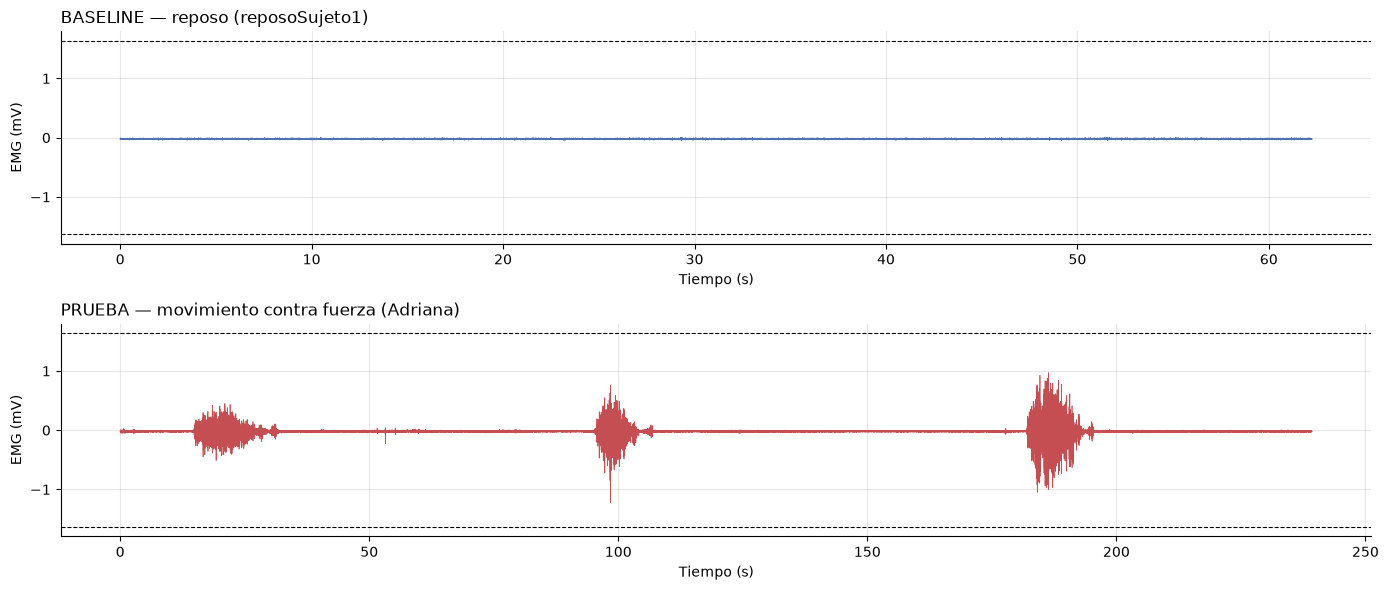

In [38]:
VCC, G_EMG = 3.3, 1009

def adc_a_mV(adc, n_bits=N_BITS, vcc=VCC, ganancia=G_EMG):
    return ((adc / 2**n_bits) - 0.5) * vcc / ganancia * 1000

emg_base_mV   = adc_a_mV(adc_base)
emg_prueba_mV = adc_a_mV(adc_prueba)
t_base   = np.arange(len(emg_base_mV)) / FS
t_prueba = np.arange(len(emg_prueba_mV)) / FS

rango_max = adc_a_mV(2**N_BITS - 1)
print(f"Rango medible del sensor: ±{rango_max:.3f} mV")
print(f"Resolución (1 cuenta ADC): {adc_a_mV(513) - adc_a_mV(512):.4f} mV = "
      f"{(adc_a_mV(513) - adc_a_mV(512))*1000:.2f} µV")

fig, ax = plt.subplots(2, 1, figsize=(14, 6), sharey=True)
ax[0].plot(t_base, emg_base_mV, lw=0.5, color=COLOR_REPOSO)
ax[0].set_title("BASELINE — reposo (reposoSujeto1)", loc="left")
ax[1].plot(t_prueba, emg_prueba_mV, lw=0.5, color=COLOR_CONTRAC)
ax[1].set_title("PRUEBA — movimiento contra fuerza (Adriana)", loc="left")
for a in ax:
    a.axhline(rango_max, ls="--", color="k", lw=0.8); a.axhline(-rango_max, ls="--", color="k", lw=0.8)
    a.set_ylabel("EMG (mV)"); a.set_xlabel("Tiempo (s)")
plt.tight_layout(); plt.show()

📘 **Explicación.** Se convirtieron las cuentas del ADC a milivoltios con la fórmula del fabricante.

- **Rango medible: ±1.632 mV** (líneas punteadas). **Resolución: 3.19 µV por cuenta.**
- El BASELINE es prácticamente una línea plana.
- La PRUEBA muestra **3 ráfagas de actividad** (alrededor de 15–32 s, 95–107 s y 182–195 s), separadas por reposos largos. Cada ráfaga dura más de 10 s: son **contracciones sostenidas**, no repeticiones cortas. La amplitud **crece de una contracción a la siguiente** (la tercera llega a ~1 mV) y **ninguna toca las líneas punteadas**.

### 2.6 Control de calidad: ¿hay saturación?
Una muestra está saturada si su valor ADC es exactamente 0 o $2^n-1$. Es importante **cuantificarlo** antes de calcular características, porque recorta los picos y distorsiona sobre todo las medidas sensibles a los extremos (curtosis, varianza).

In [39]:
sat_prueba = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 1)
sat_base   = (adc_base   <= 0) | (adc_base   >= 2**N_BITS - 1)
print(f"Saturación BASELINE: {sat_base.sum()} muestras ({100*sat_base.mean():.3f} %)")
print(f"Saturación PRUEBA  : {sat_prueba.sum()} muestras ({100*sat_prueba.mean():.3f} %)")

if sat_prueba.any():
    i0 = np.flatnonzero(sat_prueba)[0]
    sl = slice(max(0, i0 - 150), i0 + 150)
    plt.figure(figsize=(12, 3))
    plt.plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.9, color=COLOR_CONTRAC)
    plt.plot(t_prueba[sl][sat_prueba[sl]], emg_prueba_mV[sl][sat_prueba[sl]], "ko", ms=3, label="saturada")
    plt.title("Zoom a un evento de saturación"); plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.legend()
    plt.show()
else:
    print("No hay muestras saturadas: no se muestra zoom.")

Saturación BASELINE: 0 muestras (0.000 %)
Saturación PRUEBA  : 0 muestras (0.000 %)
No hay muestras saturadas: no se muestra zoom.


📘 **Explicación.** Una muestra se consideró saturada si su valor ADC era exactamente 0 o 1023. **Ni el BASELINE ni la PRUEBA tienen muestras saturadas**, así que no hay evento que mostrar en zoom.

🔎 **Verificación adicional — ¿qué tan cerca estuvimos del límite?**

En el ejemplo, el ADC se "pegaba" en 1022. La celda siguiente revisa los valores extremos de nuestra prueba y qué fracción del rango usamos.

In [40]:
# Verificación adicional: ¿qué tan cerca estuvimos de los límites del ADC?
valores, cuentas = np.unique(adc_prueba, return_counts=True)
print("5 valores ADC más bajos :", [(int(v), int(c)) for v, c in zip(valores[:5], cuentas[:5])])
print("5 valores ADC más altos :", [(int(v), int(c)) for v, c in zip(valores[-5:], cuentas[-5:])])

sat_corr = (adc_prueba <= 0) | (adc_prueba >= 2**N_BITS - 2)
print(f"\nCriterio original (0 o 1023)       : {sat_prueba.sum()} muestras")
print(f"Criterio corregido (0, 1022 o 1023): {sat_corr.sum()} muestras")

centro = 2**(N_BITS - 1)
margen = min(adc_prueba.min() - 0, (2**N_BITS - 1) - adc_prueba.max())
uso = max(centro - adc_prueba.min(), adc_prueba.max() - centro) / centro
print(f"Pico máximo de la PRUEBA: {np.abs(emg_prueba_mV).max():.3f} mV de ±{rango_max:.3f} mV posibles "
      f"-> se usó el {100*uso:.0f} % del rango (margen mínimo: {margen:.0f} cuentas)")

5 valores ADC más bajos : [(129, 1), (158, 1), (170, 1), (184, 1), (198, 1)]
5 valores ADC más altos : [(782, 1), (788, 1), (802, 1), (808, 1), (816, 1)]

Criterio original (0 o 1023)       : 0 muestras
Criterio corregido (0, 1022 o 1023): 0 muestras
Pico máximo de la PRUEBA: 1.223 mV de ±1.632 mV posibles -> se usó el 75 % del rango (margen mínimo: 129 cuentas)


📘 **Resultado de la verificación.**
- Los valores más bajos (129, 158, 170...) y más altos (...802, 808, 816) aparecen **una sola vez cada uno**: no hay ningún "amontonamiento" en un valor, que es la huella de la saturación.
- Con el criterio corregido (incluye 1022) también hay **0 muestras**.
- El pico máximo fue **1.223 mV**, el **75 % del rango**, con un margen mínimo de **129 cuentas** hasta el límite. La ganancia del sensor fue adecuada para la intensidad de esta tarea.

> ❓ **Preguntas de verificación**
> 1. ¿Qué porcentaje de muestras está saturado? ¿Te parece aceptable?
> 2. ¿Qué cambiarías en la adquisición para evitarlo?
> 3. ¿Por qué el baseline sirve como "registro de ruido" del sistema?

✅ **Respuestas**

1. **0 %** con ambos criterios (0/1023 y 0/1022/1023). Es totalmente aceptable: las características de amplitud y de forma (curtosis, varianza) no estarán distorsionadas por recorte. Aun así, la tercera contracción usó el 75 % del rango, así que **un esfuerzo algo mayor sí podría haber saturado**.
2. *(Conceptual.)* En nuestro caso no hizo falta corregir nada. Si en otra sesión se pidiera más fuerza, como la ganancia del BITalino es fija (G = 1009), habría que controlar la intensidad (por ejemplo, un porcentaje de la contracción máxima), usar un sensor con más rango o revisar la colocación. La saturación se previene **antes de grabar**; ningún filtro la repara después.
3. Con el músculo en reposo casi no hay actividad voluntaria, así que lo registrado es lo que el sistema "mide sin señal": ruido electrónico, interferencia de la red y ruido de la interfaz piel-electrodo. Por eso es el **piso de ruido**: el ADC solo varió 18 cuentas (496–514) y, tras filtrar, su RMS fue de **5.30 µV** (Bloque 3). Además, nuestro baseline se tomó **con el mismo equipo y canal, 6 minutos antes** de la prueba, así que representa bien las condiciones de la prueba (en el Bloque 4 se confirma).

---
# 3. Preprocesamiento (15 min)

### 3.1 ¿Qué queremos eliminar?
1. **Componente continua (offset)** y derivas lentas → el pasa-altos lo resuelve.
2. **Artefactos de movimiento** (< 20 Hz).
3. **Ruido de alta frecuencia** por encima de la banda útil.
4. **Interferencia de 60 Hz** de la red eléctrica.

### 3.2 Diseño de filtros
- **Pasa-banda Butterworth 20–450 Hz, orden 4:** respuesta plana en la banda de paso. Se implementa en forma **SOS** (*second-order sections*) por estabilidad numérica.
- **Notch IIR en 60 Hz, Q = 30:** elimina una banda angosta (~2 Hz) alrededor de 60 Hz.
- **Filtrado de fase cero (`sosfiltfilt` / `filtfilt`):** filtra hacia adelante y hacia atrás, sin desfase. Válido para análisis **offline**; un sistema en tiempo real (prótesis) usaría filtros causales.

> ⚠️ Condición obligatoria: $0 < f_{baja} < f_{alta} < F_s/2$.

Antes de filtrar, miremos el **espectro** (densidad espectral de potencia, PSD) estimado con el **método de Welch**, que promedia periodogramas de segmentos solapados y da una estimación más estable que una sola FFT.

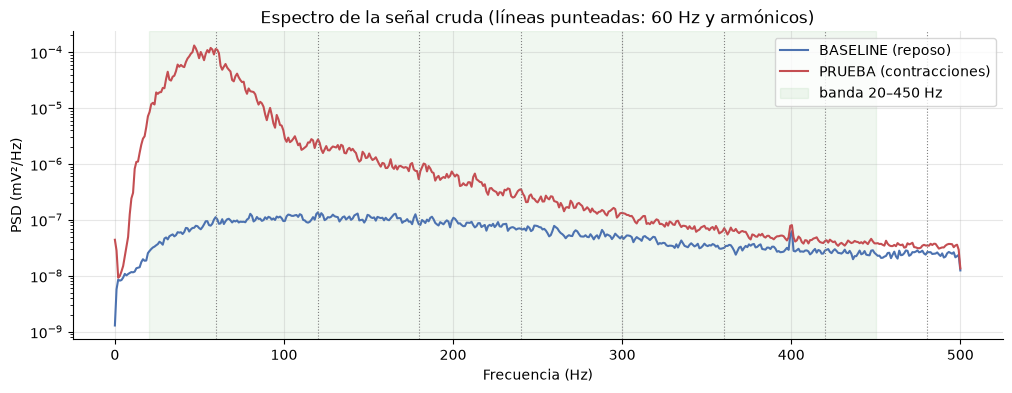

In [41]:
def psd(x, fs=FS, nperseg=1024):
    return signal.welch(x - np.mean(x), fs=fs, nperseg=nperseg)

f_b, P_b = psd(emg_base_mV)
f_p, P_p = psd(emg_prueba_mV)

plt.figure(figsize=(12, 4))
plt.semilogy(f_b, P_b, label="BASELINE (reposo)", color=COLOR_REPOSO)
plt.semilogy(f_p, P_p, label="PRUEBA (contracciones)", color=COLOR_CONTRAC)
for k in range(1, 9):
    plt.axvline(60*k, color="gray", ls=":", lw=0.8)
plt.axvspan(20, 450, color="green", alpha=0.06, label="banda 20–450 Hz")
plt.xlabel("Frecuencia (Hz)"); plt.ylabel("PSD (mV²/Hz)")
plt.title("Espectro de la señal cruda (líneas punteadas: 60 Hz y armónicos)")
plt.legend(); plt.show()

###**La PSD por el método de Welch (Power Spectral Density)**

La PSD por el método de Welch (Power Spectral Density) permite conocer cómo se distribuye la potencia de una señal entre sus diferentes frecuencias.

¿Cómo funciona?
1. Divide la señal en segmentos solapados.
2. Aplica una ventana a cada segmento para reducir la fuga espectral.
3. Calcula el periodograma de cada segmento mediante la FFT.
4. Promedia los periodogramas para obtener una estimación más estable de la PSD.
¿Para qué sirve en una señal sEMG?

Permite identificar las frecuencias donde se concentra la potencia de la actividad eléctrica muscular y calcular características como la frecuencia media y la frecuencia mediana, útiles para estudiar cambios en la señal, por ejemplo, durante la fatiga muscular.

En resumen: Welch transforma el análisis de una señal en el tiempo en una estimación de su distribución de potencia en frecuencia, reduciendo las fluctuaciones que tendría un único periodograma.

📘 **Explicación.** Espectro (PSD por Welch) en escala logarítmica:

- **BASELINE (azul):** potencia baja (~10⁻⁷ mV²/Hz) y **casi plana** entre ~30 y 450 Hz: es la forma típica del ruido de banda ancha. **No se ve un pico claro en 60 Hz** (la verificación lo cuantifica). Aparece un pequeño pico cerca de 400 Hz que no es múltiplo de 60 Hz; con estos datos no podemos determinar su origen (también aparecía en el registro del ejemplo, así que podría ser propio del equipo).
- **PRUEBA (rojo):** tiene un máximo marcado alrededor de **45–50 Hz**, unas **1000 veces** (3 divisiones) por encima del baseline. Desde ahí cae de forma progresiva y **por encima de ~350 Hz casi se junta con el baseline**: a esas frecuencias ya solo queda ruido.

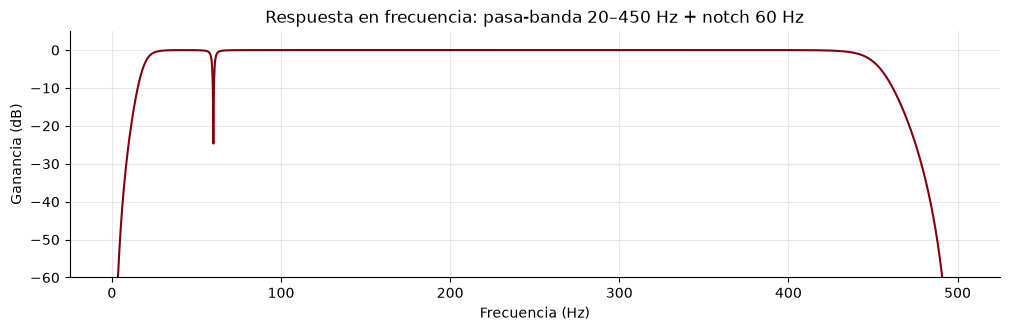

In [42]:
def filtrar_emg(x, fs=FS, f_baja=20, f_alta=450, orden=4, f_notch=60, q_notch=30):
    if not (0 < f_baja < f_alta < fs/2):
        raise ValueError(f"Se requiere 0 < f_baja < f_alta < Fs/2 (Fs = {fs} Hz).")
    sos = signal.butter(orden, [f_baja, f_alta], btype="bandpass", fs=fs, output="sos")
    y = signal.sosfiltfilt(sos, x - np.mean(x))
    if f_notch:
        b, a = signal.iirnotch(f_notch, q_notch, fs=fs)
        y = signal.filtfilt(b, a, y)
    return y

# Respuesta en frecuencia de los filtros
sos = signal.butter(4, [20, 450], btype="bandpass", fs=FS, output="sos")
w, h_bp = signal.sosfreqz(sos, worN=4096, fs=FS)
b_n, a_n = signal.iirnotch(60, 30, fs=FS)
_, h_n = signal.freqz(b_n, a_n, worN=4096, fs=FS)
plt.figure(figsize=(12, 3.2))
plt.plot(w, 20*np.log10(np.abs(h_bp*h_n) + 1e-12), color=COLOR_UPCH)
plt.ylim(-60, 5); plt.xlabel("Frecuencia (Hz)"); plt.ylabel("Ganancia (dB)")
plt.title("Respuesta en frecuencia: pasa-banda 20–450 Hz + notch 60 Hz"); plt.show()

emg_base_f   = filtrar_emg(emg_base_mV)
emg_prueba_f = filtrar_emg(emg_prueba_mV)

📘 **Explicación.** La gráfica muestra cómo trata el filtro a cada frecuencia (0 dB = la deja pasar intacta; valores negativos = la atenúa):

- Entre ~25 Hz y ~430 Hz la curva está en 0 dB: **la banda útil de la sEMG pasa sin cambios**.
- Por debajo de 20 Hz y por encima de 450 Hz la curva cae rápidamente: se eliminan las derivas lentas, los artefactos de movimiento y el ruido de alta frecuencia.
- En **60 Hz** aparece una muesca angosta: es el filtro *notch*, que elimina solo la interferencia de la red eléctrica sin afectar las frecuencias vecinas.

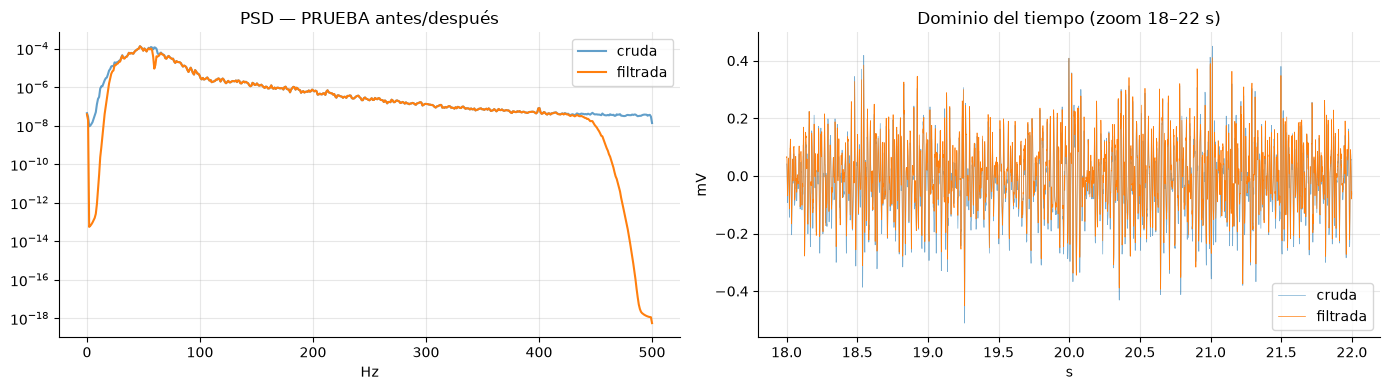

RMS del baseline filtrado (piso de ruido): 5.30 µV
RMS global de la prueba filtrada        : 57.56 µV
SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = 20.7 dB


In [43]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
f1, P1 = psd(emg_prueba_mV); f2, P2 = psd(emg_prueba_f)
ax[0].semilogy(f1, P1, label="cruda", alpha=0.7); ax[0].semilogy(f2, P2, label="filtrada")
ax[0].set_title("PSD — PRUEBA antes/después"); ax[0].set_xlabel("Hz"); ax[0].legend()

sl = (t_prueba > 18) & (t_prueba < 22)   # zoom dentro de la 1.ª contracción
ax[1].plot(t_prueba[sl], emg_prueba_mV[sl], lw=0.5, alpha=0.6, label="cruda")
ax[1].plot(t_prueba[sl], emg_prueba_f[sl], lw=0.5, label="filtrada")
ax[1].set_title("Dominio del tiempo (zoom 18–22 s)"); ax[1].set_xlabel("s"); ax[1].set_ylabel("mV"); ax[1].legend()
plt.tight_layout(); plt.show()

# Estimación simple de la relación señal-ruido usando el baseline como piso de ruido
rms = lambda x: np.sqrt(np.mean(x**2))
print(f"RMS del baseline filtrado (piso de ruido): {rms(emg_base_f)*1000:.2f} µV")
print(f"RMS global de la prueba filtrada        : {rms(emg_prueba_f)*1000:.2f} µV")
print(f"SNR aproximada = 20·log10(RMS_prueba / RMS_ruido) = "
      f"{20*np.log10(rms(emg_prueba_f)/rms(emg_base_f)):.1f} dB")

📘 **Explicación.**
- **Izquierda:** dentro de la banda 20–450 Hz las curvas coinciden; fuera de ella la filtrada cae muchos órdenes de magnitud. En 60 Hz se ve la muesca del notch, justo sobre la ladera del máximo espectral.
- **Derecha (18–22 s, dentro de la 1.ª contracción):** cruda y filtrada casi se superponen: **casi toda la energía estaba ya dentro de la banda útil**.
- **Números:**
  - RMS del baseline filtrado (ruido): **5.30 µV**.
  - RMS global de la prueba: **57.56 µV**, unas 11 veces más.
  - **SNR ≈ 20.7 dB.** Es menor que en el ejemplo (31.9 dB) **no porque la señal sea peor**, sino porque el RMS global se calcula sobre todo el registro y el **~80 % de nuestro registro es reposo**, lo que "diluye" la potencia de las contracciones. Durante las contracciones, el RMS por ventana es ~21 veces el del reposo (Bloque 5), es decir, ~26 dB.

🔎 **Verificación adicional — tamaño del pico de 60 Hz y ubicación de la energía de la contracción.**

Para responder con números las preguntas del Bloque 3, la celda siguiente calcula:
1. Cuántas veces es mayor la potencia en 60 Hz que la de sus frecuencias vecinas, antes y después de filtrar.
2. El espectro **solo de los tramos de contracción**, usando el mismo criterio de detección del Bloque 4.

In [44]:
# Verificación adicional: tamaño del pico de 60 Hz y dónde está la energía de la contracción
def pico_relativo(x, f0=60):
    f, p = signal.welch(x - np.mean(x), fs=FS, nperseg=1024)
    vecinos = p[((f > f0 - 10) & (f < f0 - 3)) | ((f > f0 + 3) & (f < f0 + 10))]
    return p[np.argmin(np.abs(f - f0))] / np.median(vecinos)

for nombre, cruda, filtrada in [("BASELINE", emg_base_mV, emg_base_f), ("PRUEBA", emg_prueba_mV, emg_prueba_f)]:
    print(f"{nombre:8s}: potencia en 60 Hz / potencia de frecuencias vecinas -> "
          f"cruda: {pico_relativo(cruda):6.1f} veces | filtrada: {pico_relativo(filtrada):5.2f} veces")

# Espectro solo de los tramos de contracción (umbral del baseline, igual que en el Bloque 4; se calcula aquí por adelantado)
env_tmp = np.sqrt(np.convolve(emg_prueba_f**2, np.ones(200)/200, mode="same"))
env_b_tmp = np.sqrt(np.convolve(emg_base_f**2, np.ones(200)/200, mode="same"))
activo_tmp = env_tmp > env_b_tmp.mean() + 5 * env_b_tmp.std()
f_c, P_c = signal.welch(emg_prueba_f[activo_tmp], fs=FS, nperseg=1024)
frac = lambda lo, hi: P_c[(f_c >= lo) & (f_c < hi)].sum() / P_c.sum()
acum = np.cumsum(P_c)
print(f"\nTramos de contracción: pico espectral en {f_c[np.argmax(P_c)]:.0f} Hz | "
      f"frecuencia mediana {f_c[np.searchsorted(acum, acum[-1]/2)]:.0f} Hz")
print(f"Fracción de potencia: 20–150 Hz = {100*frac(20,150):.1f} % | 150–450 Hz = {100*frac(150,451):.1f} % | "
      f"por debajo de 50 Hz = {100*frac(0,50):.1f} %")

BASELINE: potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    1.2 veces | filtrada:  0.13 veces
PRUEBA  : potencia en 60 Hz / potencia de frecuencias vecinas -> cruda:    1.7 veces | filtrada:  0.14 veces

Tramos de contracción: pico espectral en 47 Hz | frecuencia mediana 52 Hz
Fracción de potencia: 20–150 Hz = 97.9 % | 150–450 Hz = 2.1 % | por debajo de 50 Hz = 44.4 %


> ❓ **Preguntas de verificación**
> 1. ¿Era visible el pico de 60 Hz en el espectro crudo? ¿Desapareció tras el notch?
> 2. ¿En qué rango de frecuencias se concentra la energía durante la contracción? ¿Coincide con la teoría?
> 3. ¿Por qué no se recomienda usar un pasa-bajos de 50 Hz para "limpiar" la sEMG?

✅ **Respuestas** (con base en la verificación anterior)

1. **Apenas.** En el BASELINE la potencia en 60 Hz era solo **1.2 veces** la de las frecuencias vecinas, y en la PRUEBA **1.7 veces**: nuestra interferencia de red fue pequeña (menor que en el ejemplo, donde era 5.6 veces). **Tras el notch quedó eliminada:** la relación bajó a **0.13** (baseline) y **0.14** (prueba). Al ser menor que 1, en 60 Hz queda incluso menos potencia que en las vecinas: es la muesca del filtro.
2. En los tramos de contracción el **pico espectral está en 47 Hz** y la **frecuencia mediana en 52 Hz**. El **97.9 %** de la potencia está entre 20 y 150 Hz y solo el 2.1 % entre 150 y 450 Hz. **Coincide en parte con la teoría:** la energía está en la zona baja de la banda útil, pero nuestra señal está **más concentrada en frecuencias bajas** que el rango típico de ~50–150 Hz (en el ejemplo, el pico estaba en 76 Hz). *(Conceptual.)* Esto puede deberse al músculo, al tejido subcutáneo (que actúa como filtro pasa-bajos), a la distancia entre electrodos o al tipo de contracción; con un solo registro no podemos saber cuál pesa más.
3. Porque borraría **más de la mitad de la señal**: solo el 44.4 % de la potencia de la contracción está por debajo de 50 Hz, así que se perdería el ~56 % restante, que es actividad muscular. Además, un pasa-bajos dejaría pasar los artefactos de movimiento, que están justamente en las frecuencias más bajas. En nuestro caso, con el pico tan cerca de 50 Hz, el error sería todavía más grave porque cortaría en medio del máximo espectral.

---
# 4. Segmentación y etiquetado (10 min)

### 4.1 Envolvente y detección de actividad (*onset*)
La **envolvente RMS móvil** resume la amplitud instantánea:

$$
\text{RMS}[n] = \sqrt{\frac{1}{W}\sum_{k=n-W/2}^{n+W/2} x[k]^2}
$$

Un método clásico de detección de *onset* compara la envolvente con un **umbral** derivado del reposo:

$$
\text{umbral} = \mu_{reposo} + k\,\sigma_{reposo}
$$

Probaremos primero tomando el reposo del **archivo BASELINE**.

In [45]:
def envolvente_rms(x, fs=FS, ventana_ms=200):
    w = max(1, int(fs * ventana_ms / 1000))
    return np.sqrt(np.convolve(x**2, np.ones(w)/w, mode="same"))

env_base   = envolvente_rms(emg_base_f)
env_prueba = envolvente_rms(emg_prueba_f)

K = 5
umbral_baseline = env_base.mean() + K * env_base.std()
print(f"Umbral con el BASELINE: {umbral_baseline*1000:.1f} µV")
print(f"Fracción de la PRUEBA marcada como 'activa': {100*np.mean(env_prueba > umbral_baseline):.1f} %")

Umbral con el BASELINE: 7.7 µV
Fracción de la PRUEBA marcada como 'activa': 19.0 %


📘 **Explicación.** Se calculó la **envolvente RMS** (200 ms) y un umbral con el BASELINE: media + 5 desviaciones estándar = **7.7 µV**. El **19.0 %** de la PRUEBA lo supera. Eso es coherente con lo que se ve en la gráfica del Bloque 2: 3 contracciones de ~14 s suman ~42 s de 239 s (≈ 18 %). **Con nuestros datos, el umbral del baseline funciona** (en el ejemplo marcaba el 98 % como activo y fallaba).

### 4.2 Una sorpresa al revés (y la misma lección)
En el ejemplo, el reposo dentro de la prueba era distinto al baseline y por eso el umbral del baseline fallaba; la solución fue estimar el reposo con **el 20 % de muestras de menor envolvente de la propia prueba**. Probemos esa misma estrategia con nuestro registro.

In [46]:
# Comparación: umbral con reposo intra-registro (20 % de muestras de menor envolvente), como en el ejemplo
ref = env_prueba[env_prueba <= np.percentile(env_prueba, 20)]
umbral_intra = ref.mean() + K * ref.std()
print(f"Umbral con reposo intra-registro: {umbral_intra*1000:.1f} µV "
      f"-> marca como 'activa' el {100*np.mean(env_prueba > umbral_intra):.1f} % de la PRUEBA")

def limpiar_mascara(activo, fs=FS, hueco_min_s=0.25, dur_min_s=0.30):
    # Une segmentos separados por huecos cortos y elimina activaciones demasiado breves
    d = np.diff(np.r_[0, activo.astype(int), 0])
    inicios, fines = np.flatnonzero(d == 1), np.flatnonzero(d == -1)
    segs = []
    for s, e in zip(inicios, fines):
        if segs and s - segs[-1][1] < hueco_min_s * fs:
            segs[-1] = (segs[-1][0], e)
        else:
            segs.append((s, e))
    segs = [(s, e) for s, e in segs if (e - s) >= dur_min_s * fs]
    mascara = np.zeros(len(activo), dtype=bool)
    for s, e in segs:
        mascara[s:e] = True
    return mascara, segs

_, segs_intra = limpiar_mascara(env_prueba > umbral_intra)
_, segs_base  = limpiar_mascara(env_prueba > umbral_baseline)
print(f"Activaciones detectadas con umbral intra-registro: {len(segs_intra)}")
print(f"Activaciones detectadas con umbral del baseline : {len(segs_base)}")
print("  (inicio–fin en s):", [(round(s/FS, 1), round(e/FS, 1)) for s, e in segs_base])

Umbral con reposo intra-registro: 5.5 µV -> marca como 'activa' el 44.1 % de la PRUEBA
Activaciones detectadas con umbral intra-registro: 38
Activaciones detectadas con umbral del baseline : 10
  (inicio–fin en s): [(np.float64(0.1), np.float64(1.0)), (np.float64(14.7), np.float64(31.8)), (np.float64(40.1), np.float64(40.6)), (np.float64(52.9), np.float64(53.4)), (np.float64(58.7), np.float64(60.1)), (np.float64(76.6), np.float64(77.0)), (np.float64(95.2), np.float64(104.2)), (np.float64(104.8), np.float64(107.0)), (np.float64(177.6), np.float64(177.9)), (np.float64(181.8), np.float64(195.5))]


📘 **Explicación.**

| Umbral | Valor | % de la prueba "activo" | Activaciones detectadas |
|---|---|---|---|
| Reposo intra-registro (20 % menor) | 5.5 µV | 44.1 % | **38** |
| BASELINE | 7.7 µV | 19.0 % | **10** |

Con nuestros datos ocurre **lo contrario que en el ejemplo**: el umbral intra-registro es **demasiado bajo** y fragmenta el reposo en 38 "activaciones". La razón es que nuestro registro es ~80 % reposo: el 20 % de muestras de menor envolvente es solo **el reposo más tranquilo**, con una dispersión muy pequeña, y media + 5σ queda apenas por encima del nivel de reposo normal.

Con el umbral del baseline aparecen 10 activaciones: **las 3 contracciones sostenidas** y 7 eventos breves (de 0.3 a 2.2 s), como el del inicio (0.1–1.0 s, efecto de borde del filtro al empezar el registro) o pequeños movimientos entre contracciones (~40, 53, 59, 77 y 178 s), además de una prolongación al final de la 2.ª contracción (104.8–107.0 s).

**Lección (la misma del ejemplo, vista desde el otro lado):** la referencia de reposo debe representar **las mismas condiciones** que la señal. Aquí el baseline grabado 6 min antes con el mismo equipo cumple esa condición; el atajo del "20 % menor" no, porque depende de qué proporción del registro es reposo.

### 4.3 Detección final
Usamos el **umbral del baseline** con dos máscaras:
- `mascara_cualquier`: toda actividad sobre el umbral (incluye los movimientos breves).
- `contracciones`: solo las activaciones de la tarea, uniendo huecos < 1 s y exigiendo **≥ 2 s** de duración. Este criterio es más estricto que en el ejemplo (0.25 s / 0.30 s) porque nuestra tarea fue de **contracciones sostenidas de más de 10 s**; un evento de menos de 2 s no corresponde a la tarea.

Umbral usado: 7.7 µV
Contracciones sostenidas detectadas: 3 | duración media 14.15 ± 2.18 s
  Contracción 1:  14.74 –  31.79 s  (17.04 s)
  Contracción 2:  95.21 – 107.00 s  (11.78 s)
  Contracción 3: 181.83 – 195.47 s  (13.64 s)


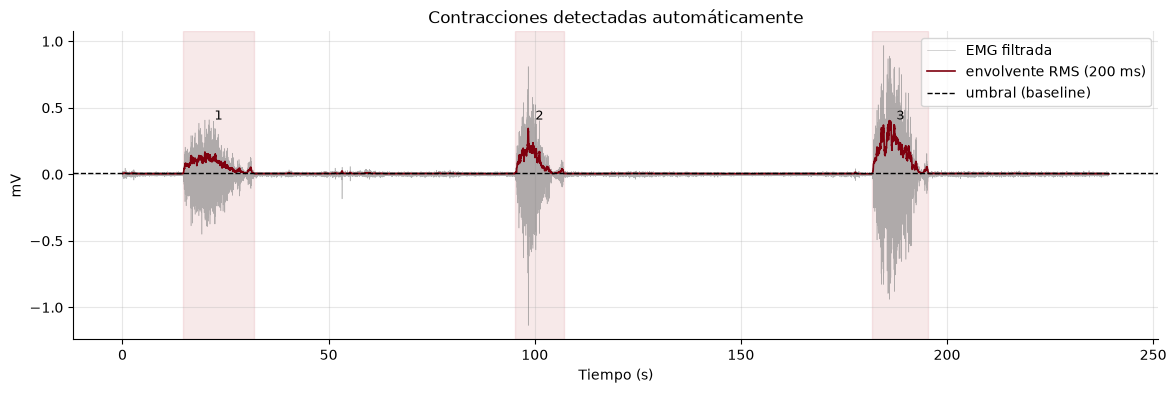

In [47]:
# Detección final: umbral del BASELINE.
# 1) mascara_cualquier: toda actividad sobre el umbral (incluye movimientos breves)
# 2) contracciones: solo las activaciones sostenidas de la tarea (>= 2 s, uniendo huecos < 1 s)
umbral = umbral_baseline
mascara_cualquier, _ = limpiar_mascara(env_prueba > umbral)
mascara_activa, contracciones = limpiar_mascara(env_prueba > umbral, hueco_min_s=1.0, dur_min_s=2.0)
dur = np.array([(e - s) / FS for s, e in contracciones])
print(f"Umbral usado: {umbral*1000:.1f} µV")
print(f"Contracciones sostenidas detectadas: {len(contracciones)} | duración media {dur.mean():.2f} ± {dur.std():.2f} s")
for i, (s, e) in enumerate(contracciones):
    print(f"  Contracción {i+1}: {s/FS:6.2f} – {e/FS:6.2f} s  ({(e-s)/FS:.2f} s)")

plt.figure(figsize=(14, 4))
plt.plot(t_prueba, emg_prueba_f, lw=0.4, color="gray", alpha=0.6, label="EMG filtrada")
plt.plot(t_prueba, env_prueba, lw=1.2, color=COLOR_UPCH, label="envolvente RMS (200 ms)")
plt.axhline(umbral, color="k", ls="--", lw=1, label="umbral (baseline)")
for i, (s, e) in enumerate(contracciones):
    plt.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.12)
    plt.text((s+e)/2/FS, env_prueba.max()*1.02, str(i+1), ha="center", fontsize=9)
plt.xlabel("Tiempo (s)"); plt.ylabel("mV"); plt.title("Contracciones detectadas automáticamente")
plt.legend(loc="upper right"); plt.show()

📘 **Explicación.** Se detectaron **3 contracciones sostenidas** de **14.15 ± 2.18 s**:

| Contracción | Inicio – fin | Duración |
|---|---|---|
| 1 | 14.74 – 31.79 s | 17.04 s |
| 2 | 95.21 – 107.00 s | 11.78 s |
| 3 | 181.83 – 195.47 s | 13.64 s |

Las franjas rosadas coinciden con las 3 ráfagas visibles. En la envolvente se ve que **cada contracción sube rápido, alcanza su máximo en los primeros segundos y luego decae poco a poco** hasta el reposo: la fuerza no se mantuvo constante. También se ve que la amplitud máxima crece de la 1.ª a la 3.ª contracción.

### 4.4 Ventaneo
Las características se calculan sobre **ventanas** cortas, porque la sEMG es **no estacionaria**.

| Parámetro | Valor | Compromiso |
|---|---|---|
| Longitud de ventana | 250 ms | Más corta → mejor resolución temporal, pero estimaciones más ruidosas |
| Solapamiento | 50 % | Más observaciones, pero **no independientes** entre sí |

**Etiquetado de cada ventana** (adaptado):
- `contraccion` si ≥ 80 % de sus muestras están dentro de una **contracción sostenida**.
- `reposo` si ≤ 5 % de sus muestras tienen **cualquier** actividad (así, los movimientos breves entre contracciones no se cuelan como "reposo").
- `transicion` en otro caso (se excluye del entrenamiento).

Además guardamos el **identificador de grupo** (`ciclo`): el reposo previo a la contracción *i* y la propia contracción *i* forman el ciclo *i*; el reposo final se une al último ciclo.

In [48]:
def crear_ventanas(x, fs=FS, ventana_ms=250, solapamiento=0.5):
    n = int(round(fs * ventana_ms / 1000))
    paso = max(1, int(round(n * (1 - solapamiento))))
    inicios = np.arange(0, len(x) - n + 1, paso)
    return np.stack([x[i:i+n] for i in inicios]), inicios

def etiquetar(inicios, n):
    # contraccion: >= 80 % dentro de una contracción sostenida
    # reposo     : <= 5 % de CUALQUIER actividad (así los movimientos breves no contaminan el reposo)
    fa = np.array([mascara_activa[i:i+n].mean() for i in inicios])
    fc = np.array([mascara_cualquier[i:i+n].mean() for i in inicios])
    return np.where(fa >= 0.8, "contraccion", np.where(fc <= 0.05, "reposo", "transicion"))

def asignar_ciclo(inicios, n, et):
    # Ciclo i = reposo previo a la contracción i + la contracción i (el reposo final va al último ciclo)
    c = np.searchsorted(inicios_contr, inicios + n // 2, side="right") - 1
    c = np.where(et == "reposo", np.searchsorted(inicios_contr, inicios, side="left"), c)
    return np.clip(c, 0, len(contracciones) - 1)

VENTANA_MS, SOLAP = 250, 0.5
ventanas, inicios = crear_ventanas(emg_prueba_f, FS, VENTANA_MS, SOLAP)
n_win = ventanas.shape[1]
inicios_contr = np.array([s for s, _ in contracciones])

etiqueta = etiquetar(inicios, n_win)
ciclo = asignar_ciclo(inicios, n_win, etiqueta)
ventana_saturada = np.array([sat_prueba[i:i+n_win].any() for i in inicios])

print(f"Ventanas: {len(ventanas)} de {n_win} muestras ({VENTANA_MS} ms, solapamiento {int(SOLAP*100)} %)")
print(pd.Series(etiqueta).value_counts().to_string())
print(f"Ventanas con al menos una muestra saturada: {ventana_saturada.sum()}")


Ventanas: 1913 de 250 muestras (250 ms, solapamiento 50 %)
reposo         1524
contraccion     336
transicion       53
Ventanas con al menos una muestra saturada: 0


📘 **Explicación.** La señal filtrada se dividió en **1913 ventanas** de 250 ms (una nueva cada 125 ms):

| Etiqueta | Nº de ventanas |
|---|---|
| reposo | 1524 |
| contracción | 336 |
| transición | 53 (se excluyen) |

No hay ninguna ventana saturada. Las clases están **desbalanceadas** (~4.5 ventanas de reposo por cada una de contracción), por eso más adelante usaremos la **exactitud balanceada**. Además, los ciclos son **muy desiguales**

---
# 5. Extracción de características clásicas (25 min)

Una **característica** es una función $f: \mathbb{R}^N \rightarrow \mathbb{R}$ que transforma una ventana de $N$ muestras en un número con significado. Las revisiones sistemáticas sobre reconocimiento de patrones mioeléctricos las agrupan en familias. Trabajaremos con cuatro.

### 5.1 Familia de amplitud / energía
*¿Cuánta actividad hay?* Crecen con el reclutamiento y la frecuencia de disparo.

| Característica | Fórmula | Intuición |
|---|---|---|
| **MAV** (*Mean Absolute Value*) | $\frac{1}{N}\sum_{i=1}^{N}\lvert x_i\rvert$ | Amplitud media rectificada |
| **RMS** (*Root Mean Square*) | $\sqrt{\frac{1}{N}\sum x_i^2}$ | Relacionada con la potencia de la señal |
| **iEMG** (EMG integrada) | $\sum \lvert x_i\rvert$ | Área bajo la señal rectificada |
| **VAR** | $\frac{1}{N-1}\sum (x_i-\bar{x})^2$ | Potencia (la sEMG filtrada tiene media ≈ 0) |

> ⚠️ RMS ≠ fuerza. La relación amplitud-fuerza depende del músculo, es no lineal y requiere normalización (p. ej., respecto de una contracción voluntaria máxima, %MVC) para comparar sujetos o sesiones.

### 5.2 Familia de complejidad / forma de onda
*¿Qué tan rápido y cuánto cambia la señal?* Forman el conjunto clásico propuesto por **Hudgins et al. (1993)** para control de prótesis. Las tres últimas usan un **umbral de ruido** $\varepsilon$ para no contar fluctuaciones del piso de ruido; lo tomaremos del baseline: $\varepsilon = 3\,\sigma_{baseline}$.

| Característica | Definición | Intuición |
|---|---|---|
| **WL** (*Waveform Length*) | $\sum_{i=1}^{N-1}\lvert x_{i+1}-x_i\rvert$ | "Longitud del trazo": combina amplitud y frecuencia |
| **ZC** (*Zero Crossings*) | nº de veces que $x$ cambia de signo con $\lvert x_{i}-x_{i+1}\rvert \ge \varepsilon$ | Estimador temporal de frecuencia |
| **SSC** (*Slope Sign Changes*) | nº de cambios de signo de la pendiente que superan $\varepsilon$ | Densidad de picos |
| **WAMP** (*Willison Amplitude*) | nº de veces que $\lvert x_{i+1}-x_i\rvert > \varepsilon$ | Relacionada con el disparo de unidades motoras |

### 5.3 Familia estadística (forma de la distribución)
*¿Se parecen las amplitudes a una campana de Gauss?*

| Característica | Fórmula | Interpretación |
|---|---|---|
| **Asimetría** (*skewness*) | $\frac{E[(x-\mu)^3]}{\sigma^3}$ | 0 = distribución simétrica |
| **Curtosis de Fisher** | $\frac{E[(x-\mu)^4]}{\sigma^4}-3$ | 0 = gaussiana; > 0 = colas pesadas / picos aislados; < 0 = distribución "aplanada" |

En contracciones con muchas UM, la sEMG tiende a ser cuasi-gaussiana (curtosis cercana a 0). Con pocas UM, o con artefactos, aparecen picos aislados (curtosis alta). La **saturación** recorta las colas y empuja la curtosis hacia valores **negativos**.

### 5.4 Familia espectral
*¿De qué "tonos" está hecha la señal?* A partir de la PSD $P(f)$ por Welch:

| Característica | Fórmula | Interpretación |
|---|---|---|
| **MNF** (frecuencia media) | $\dfrac{\sum f_j P_j}{\sum P_j}$ | Centro de masa del espectro |
| **MDF** (frecuencia mediana) | $f_{med}$ tal que $\sum_{f\le f_{med}} P = \tfrac12 \sum P$ | Divide la potencia en dos mitades; más robusta al ruido |
| **Potencia por bandas** | fracción de potencia en 20–80, 80–150 y 150–450 Hz | Distribución espectral gruesa |

> 💡 **Fatiga muscular:** al fatigarse, disminuye la velocidad de conducción de las fibras y los MUAPs se "ensanchan" → el espectro se desplaza a frecuencias **más bajas** → **MDF y MNF disminuyen**, mientras el RMS suele **aumentar**. Es uno de los indicadores de fatiga más usados.

In [49]:
EPS = 3 * np.std(emg_base_f)   # umbral de ruido para ZC, SSC y WAMP
print(f"Umbral de ruido ε = {EPS*1000:.1f} µV")

def caracteristicas_temporales(x, eps=EPS):
    dx = np.diff(x)
    zc   = np.sum((x[:-1] * x[1:] < 0) & (np.abs(dx) >= eps))
    ssc  = np.sum(((dx[:-1] * dx[1:]) < 0) & ((np.abs(dx[:-1]) >= eps) | (np.abs(dx[1:]) >= eps)))
    return {
        "MAV":  np.mean(np.abs(x)),
        "RMS":  np.sqrt(np.mean(x**2)),
        "iEMG": np.sum(np.abs(x)),
        "VAR":  np.var(x, ddof=1),
        "WL":   np.sum(np.abs(dx)),
        "ZC":   zc,
        "SSC":  ssc,
        "WAMP": np.sum(np.abs(dx) > eps),
        "Asimetria": skew(x),
        "Curtosis":  kurtosis(x, fisher=True, bias=False),
    }

def caracteristicas_frecuenciales(x, fs=FS, nperseg=128):
    f, p = signal.welch(x, fs=fs, nperseg=min(nperseg, len(x)))
    banda = (f >= 20) & (f <= 450)
    f, p = f[banda], p[banda]
    p_tot = p.sum()
    acum = np.cumsum(p)
    pot = lambda lo, hi: p[(f >= lo) & (f < hi)].sum() / p_tot
    return {
        "MNF": np.sum(f * p) / p_tot,
        "MDF": f[np.searchsorted(acum, acum[-1] / 2)],
        "P_20_80":   pot(20, 80),
        "P_80_150":  pot(80, 150),
        "P_150_450": pot(150, 451),
    }

def extraer_caracteristicas(x, fs=FS):
    c = caracteristicas_temporales(x)
    c.update(caracteristicas_frecuenciales(x, fs))
    return c

# Prueba con una sola ventana de cada clase
i_rep = np.flatnonzero(etiqueta == "reposo")[3]
i_con = np.flatnonzero(etiqueta == "contraccion")[3]
display(pd.DataFrame({"reposo": extraer_caracteristicas(ventanas[i_rep]),
                      "contraccion": extraer_caracteristicas(ventanas[i_con])}).round(4))

Umbral de ruido ε = 15.9 µV


,reposo,contraccion
MAV,0.0041,0.0617
RMS,0.0050,0.0782
iEMG,1.0140,15.4232
VAR,0.0000,0.0061
WL,1.1060,5.7722
ZC,0.0000,27.0000
SSC,0.0000,25.0000
WAMP,0.0000,154.0000
Asimetria,-0.0714,-0.0318
Curtosis,-0.0708,-0.1529


📘 **Explicación.** El **umbral de ruido es ε = 15.9 µV** (3 veces la desviación estándar del baseline). Luego se calcularon las 15 características para **una ventana de ejemplo** de cada clase:
- **Amplitud:** el RMS pasa de 0.0050 a 0.0782 mV (~16 veces más).
- **Complejidad:** en reposo, ZC, SSC y WAMP valen **0**: ningún cambio de la señal en reposo supera ε. En contracción: ZC = 27, SSC = 25, WAMP = 154.
- **Espectrales:** la MDF cae de **164 a 39 Hz** y la potencia en 150–450 Hz de **54 % a 1.3 %**. El espectro del reposo (ruido plano) tiene su "centro" en frecuencias altas; el de la contracción, en frecuencias bajas.

⚠️ Son solo dos ventanas; las conclusiones se sacan de los promedios (celda siguiente).

In [50]:
df = pd.DataFrame([extraer_caracteristicas(w) for w in ventanas])
CARACTERISTICAS = list(df.columns)
df.insert(0, "t_inicio_s", inicios / FS)
df["etiqueta"] = etiqueta
df["ciclo"] = ciclo
df["saturada"] = ventana_saturada

print("Matriz de características:", df[CARACTERISTICAS].shape, "(ventanas × características)")
display(df.head())
display(df.groupby("etiqueta")[CARACTERISTICAS].mean().T.round(4))

Matriz de características: (1913, 15) (ventanas × características)


,t_inicio_s,MAV,RMS,iEMG,VAR,WL,ZC,SSC,WAMP,Asimetria,Curtosis,MNF,MDF,P_20_80,P_80_150,P_150_450,etiqueta,ciclo,saturada
0,0.000,0.005793,0.007643,1.448143,0.000059,1.520716,10,13,11,0.069885,1.805147,162.024285,117.1875,0.242539,0.344893,0.412568,transicion,0,False
1,0.125,0.005784,0.007395,1.445921,0.000055,1.434801,9,14,10,-0.111419,1.519846,152.772368,109.3750,0.393234,0.208424,0.398342,transicion,0,False
2,0.250,0.006022,0.007557,1.505403,0.000057,1.492644,7,13,10,0.070716,0.838471,149.970389,125.0000,0.379734,0.236463,0.383803,transicion,0,False
3,0.375,0.006389,0.008245,1.597239,0.000068,1.654493,13,18,17,-0.287324,1.162636,169.806787,140.6250,0.136505,0.448976,0.414518,transicion,0,False
4,0.500,0.006681,0.009168,1.670263,0.000084,1.636658,12,14,20,0.633469,3.730047,127.422297,117.1875,0.326393,0.419323,0.254284,transicion,0,False


etiqueta,contraccion,reposo,transicion
MAV,0.0842,0.0042,0.0064
RMS,0.1070,0.0052,0.0087
iEMG,21.0449,1.0466,1.5968
VAR,0.0188,0.0000,0.0001
WL,8.6974,1.1394,1.3981
ZC,24.3929,1.9508,5.5849
SSC,35.1399,2.4173,7.1887
WAMP,136.1071,2.2041,9.0566
Asimetria,-0.2421,0.1697,0.0834
Curtosis,0.8229,0.2607,2.4986


📘 **Explicación.** Matriz de características: **1913 ventanas × 15 características** (más tiempo, etiqueta, ciclo y saturación). Promedios por clase:

| Característica | Reposo | Contracción | Lectura |
|---|---|---|---|
| RMS (mV) | 0.0052 | 0.1070 | ~21 veces más amplitud en contracción |
| ZC | 1.95 | 24.39 | ~12 veces más cruces por cero |
| WAMP | 2.20 | 136.11 | ~60 veces más cambios grandes |
| Curtosis | 0.26 | 0.82 | Ambas cercanas a 0 (casi gaussianas) |
| MDF (Hz) | 157.1 | 60.2 | **~97 Hz menor** en contracción |
| MNF (Hz) | 178.9 | 70.4 | ~108 Hz menor en contracción |
| P_150_450 | 0.51 | 0.06 | El reposo tiene la mitad de su potencia en altas frecuencias |

**Diferencia importante con el ejemplo:** allí la MDF de reposo y contracción era parecida (62 vs 73 Hz). En nuestro caso el reposo es **ruido casi puro** (espectro plano → MDF alta), mientras que la contracción concentra su energía cerca de 50 Hz. Por eso las características espectrales separan muy bien las clases en nuestros datos.

### 5.5 Visualización temporal de las características
Observa cómo cada familia "responde" a las contracciones.

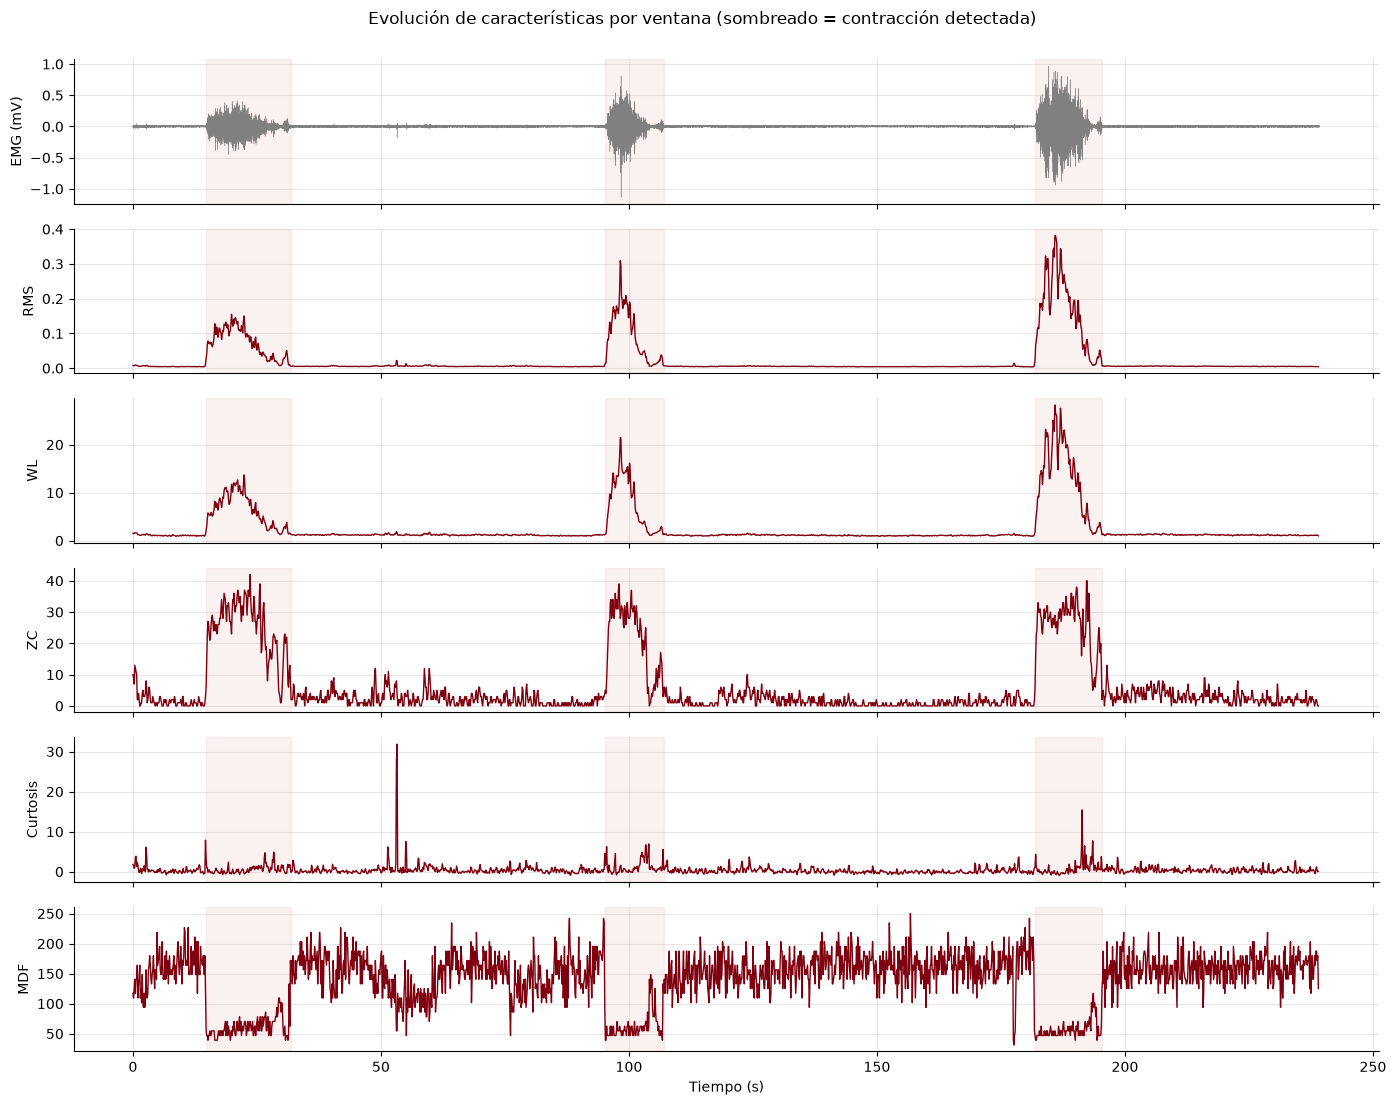

In [51]:
mostrar = ["RMS", "WL", "ZC", "Curtosis", "MDF"]
fig, ax = plt.subplots(len(mostrar) + 1, 1, figsize=(14, 11), sharex=True)
ax[0].plot(t_prueba, emg_prueba_f, lw=0.3, color="gray")
ax[0].set_ylabel("EMG (mV)")
for a, c in zip(ax[1:], mostrar):
    a.plot(df["t_inicio_s"], df[c], lw=1, color=COLOR_UPCH)
    a.set_ylabel(c)
for a in ax:
    for s, e in contracciones:
        a.axvspan(s/FS, e/FS, color=COLOR_CONTRAC, alpha=0.08)
ax[-1].set_xlabel("Tiempo (s)")
plt.suptitle("Evolución de características por ventana (sombreado = contracción detectada)", y=1.0)
plt.tight_layout(); plt.show()

📘 **Explicación.** Cada fila es una característica en el tiempo; las franjas son las contracciones.

- **RMS y WL:** suben en cada contracción y son casi nulas en reposo. Se ve claramente el perfil de cada contracción: subida rápida, máximo al inicio y descenso gradual. El máximo crece de la 1.ª (~0.15 mV) a la 3.ª (~0.38 mV).
- **ZC:** salta de ~0–5 a ~25–40 en cada contracción, como un "escalón". Fuera de las contracciones tiene pequeñas subidas (por ejemplo, entre 40 y 75 s) que coinciden con los movimientos breves.
- **Curtosis:** cerca de 0 casi todo el tiempo, con picos aislados (el mayor, ~32, cerca de 53 s, que coincide con uno de los movimientos breves). No separa las clases.
- **MDF:** el patrón es **inverso** al del RMS: ~150–200 Hz en reposo y cae bruscamente a ~50 Hz en cada contracción. Dentro de cada contracción la MDF **sube** de forma gradual hacia el final, a medida que baja la amplitud (se analiza en el Ejercicio 2).

### 5.6 ¿Qué característica separa mejor las clases?
Usaremos dos herramientas:
1. **Boxplots por clase**, para una inspección visual.
2. **Razón de Fisher** para cada característica: $J = \dfrac{(\mu_1-\mu_2)^2}{\sigma_1^2+\sigma_2^2}$. Mide la separación entre medias en relación con la dispersión. Cuanto mayor, más discriminante.

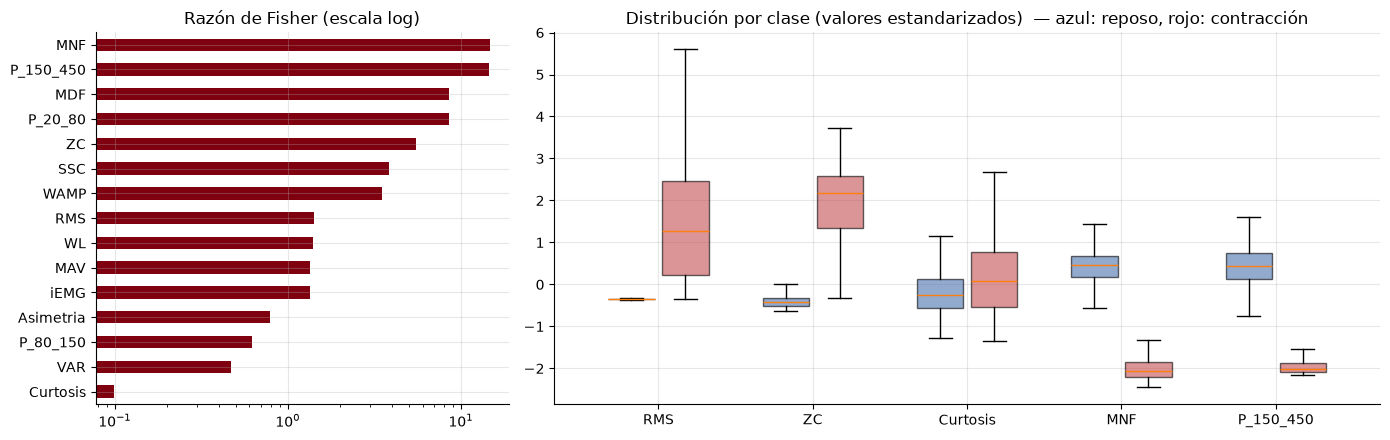

MNF          14.68
P_150_450    14.52
MDF           8.58
P_20_80       8.53
ZC            5.52
SSC           3.83
WAMP          3.48
RMS           1.42
WL            1.40
MAV           1.34
iEMG          1.34
Asimetria     0.79
P_80_150      0.62
VAR           0.47
Curtosis      0.10


In [52]:
df_ml = df[df["etiqueta"] != "transicion"].copy()
r, c = df_ml[df_ml.etiqueta == "reposo"], df_ml[df_ml.etiqueta == "contraccion"]
fisher = ((r[CARACTERISTICAS].mean() - c[CARACTERISTICAS].mean())**2 /
          (r[CARACTERISTICAS].var() + c[CARACTERISTICAS].var())).sort_values(ascending=False)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), gridspec_kw={"width_ratios": [1, 2]})
fisher.plot.barh(ax=ax[0], color=COLOR_UPCH); ax[0].invert_yaxis()
ax[0].set_xscale("log"); ax[0].set_title("Razón de Fisher (escala log)")

seleccion = ["RMS", "ZC", "Curtosis", "MNF", "P_150_450"]
datos_z = (df_ml[seleccion] - df_ml[seleccion].mean()) / df_ml[seleccion].std()
pos = np.arange(len(seleccion))
for k, (lab, col) in enumerate([("reposo", COLOR_REPOSO), ("contraccion", COLOR_CONTRAC)]):
    bp = ax[1].boxplot([datos_z[df_ml.etiqueta == lab][s] for s in seleccion],
                       positions=pos + (k - 0.5) * 0.35, widths=0.3, patch_artist=True, showfliers=False)
    for b in bp["boxes"]:
        b.set_facecolor(col); b.set_alpha(0.6)
ax[1].set_xticks(pos); ax[1].set_xticklabels(seleccion)
ax[1].set_title("Distribución por clase (valores estandarizados)  — azul: reposo, rojo: contracción")
plt.tight_layout(); plt.show()
print(fisher.round(2).to_string())

📘 **Explicación.** Ranking de la **razón de Fisher**:
- **MNF (14.68), P_150_450 (14.52), MDF (8.58) y P_20_80 (8.53):** las más discriminantes, todas **espectrales**.
- ZC (5.52), SSC (3.83) y WAMP (3.48): nivel alto-intermedio.
- RMS (1.42), WL (1.40), iEMG y MAV (1.34): intermedio.
- Asimetría (0.79), P_80_150 (0.62), VAR (0.47) y **curtosis (0.10)**: casi no separan.

En los **boxplots** (valores estandarizados): en MNF y P_150_450 las cajas de reposo y contracción **no se tocan** y ambas son estrechas. En RMS la caja de contracción está desplazada, pero es **muy ancha**. En curtosis las cajas se superponen casi por completo.

**¿Por qué el RMS queda tan abajo si en la gráfica se veía tan limpio?** Igual que en el ejemplo, Fisher castiga la dispersión: el RMS de la contracción varía muchísimo (desviación estándar 0.0855 mV contra 0.0007 mV en reposo, ver Bloque 6), porque la fuerza cambió durante cada contracción y entre contracciones. Las espectrales, en cambio, son estables dentro de cada clase.

### 5.7 El efecto de la saturación sobre la curtosis
En nuestro registro **no hay ventanas saturadas**, así que la comparación del ejemplo no se puede hacer. Como alternativa, comparamos la curtosis de las ventanas de contracción **más débiles** (25 % de menor RMS) con las **más intensas** (25 % de mayor RMS).

Ventanas de contracción con saturación: 0 de 336


,25 % más débiles,25 % más intensas
RMS,0.019,0.228
Curtosis,1.439,0.078
Asimetria,-0.266,-0.145
MDF,75.056,53.292


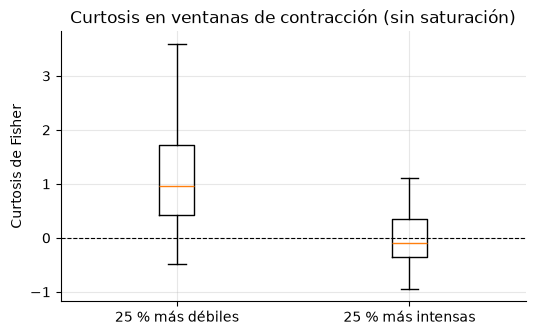

In [53]:
con = df[df.etiqueta == "contraccion"]
print(f"Ventanas de contracción con saturación: {int(con['saturada'].sum())} de {len(con)}")
if con["saturada"].any():
    display(con.groupby("saturada")[["RMS", "Curtosis", "Asimetria", "MDF"]].agg(["mean", "count"]).round(3))
    plt.figure(figsize=(6, 3.5))
    plt.boxplot([con[~con.saturada]["Curtosis"], con[con.saturada]["Curtosis"]], showfliers=False)
    plt.xticks([1, 2], ["sin saturación", "con saturación"])
    plt.axhline(0, color="k", lw=0.8, ls="--")
    plt.ylabel("Curtosis de Fisher"); plt.title("Curtosis en ventanas de contracción")
    plt.show()
else:
    # Sin saturación no hay comparación posible. Como alternativa, comparamos la curtosis
    # de las ventanas de contracción más intensas (cuartil superior de RMS) vs. las más débiles.
    q1, q3 = con["RMS"].quantile([0.25, 0.75])
    debil, fuerte = con[con.RMS <= q1], con[con.RMS >= q3]
    display(pd.DataFrame({"25 % más débiles": debil[["RMS", "Curtosis", "Asimetria", "MDF"]].mean(),
                          "25 % más intensas": fuerte[["RMS", "Curtosis", "Asimetria", "MDF"]].mean()}).round(3))
    plt.figure(figsize=(6, 3.5))
    plt.boxplot([debil["Curtosis"], fuerte["Curtosis"]], showfliers=False)
    plt.xticks([1, 2], ["25 % más débiles", "25 % más intensas"])
    plt.axhline(0, color="k", lw=0.8, ls="--")
    plt.ylabel("Curtosis de Fisher"); plt.title("Curtosis en ventanas de contracción (sin saturación)")
    plt.show()

📘 **Explicación.** **0 de 336** ventanas de contracción tienen saturación. En la comparación alternativa:

| | 25 % más débiles | 25 % más intensas |
|---|---|---|
| RMS medio | 0.019 mV | 0.228 mV |
| Curtosis media | **1.44** | **0.08** |
| MDF media | 75.1 Hz | 53.3 Hz |

Las ventanas más intensas tienen curtosis **prácticamente 0 (gaussiana)**, y las más débiles, curtosis positiva. Es lo que predice la teoría (Bloque 5.3): con muchas unidades motoras activas, la suma se parece a una campana de Gauss; con pocas (o cuando la señal se acerca al piso de ruido), aparecen picos aislados que elevan la curtosis. **Aquí la curtosis no está afectada por recorte**, así que refleja la fisiología y no un artefacto.

🔎 **Verificación adicional — ¿son redundantes las características de amplitud?**

La celda siguiente calcula la correlación entre MAV, RMS, iEMG, VAR y WL. Una correlación de 1 significa que dos características suben y bajan exactamente juntas.

In [54]:
# Verificación adicional: ¿las características de amplitud son redundantes?
amp = ["MAV", "RMS", "iEMG", "VAR", "WL"]
print("Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):")
display(df_ml[amp].corr().round(3))

Correlación de Pearson entre características de amplitud (ventanas de reposo y contracción):


,MAV,RMS,iEMG,VAR,WL
MAV,1.000,0.999,1.000,0.936,0.994
RMS,0.999,1.000,0.999,0.932,0.994
iEMG,1.000,0.999,1.000,0.936,0.994
VAR,0.936,0.932,0.936,1.000,0.917
WL,0.994,0.994,0.994,0.917,1.000


> ❓ **Preguntas de verificación**
> 1. ¿Qué características quedaron arriba en el ranking de Fisher? ZC, SSC y WAMP usan el umbral ε: ¿miden solo "frecuencia" o también amplitud? Justifica.
> 2. ¿Por qué RMS, MAV, iEMG y VAR obtienen rankings tan parecidos? ¿Aportan información distinta? (Pista: correlación / redundancia).
> 3. ¿Cómo cambia la curtosis en las ventanas saturadas? ¿Qué harías con esas ventanas en un estudio real?

✅ **Respuestas**

1. Arriba quedaron las **espectrales: MNF (14.68), P_150_450 (14.52), MDF (8.58)**; después vienen ZC (5.52), SSC (3.83) y WAMP (3.48). Estas tres **también miden amplitud**: solo cuentan un evento si el cambio supera ε = 15.9 µV. La prueba más clara está en nuestros datos: en la ventana de reposo de ejemplo, ZC, SSC y WAMP valen **0**, no porque la señal no cruce el cero (el ruido lo cruza constantemente), sino porque ningún cambio supera ε. En promedio, WAMP pasa de 2.2 en reposo a 136.1 en contracción. Son una **mezcla de amplitud y frecuencia**.
2. Porque **miden prácticamente lo mismo**. Correlaciones: MAV–RMS **0.999**, MAV–iEMG **1.000** (con ventanas de tamaño fijo, iEMG = N · MAV), WL con ellas **0.994**; VAR algo menos (0.917–0.936) porque es el cuadrado del RMS y no crece de forma lineal. **No aportan información distinta**; en un clasificador basta con una o dos (por ejemplo, RMS y WL). Sus razones de Fisher son casi iguales (1.34–1.42) por la misma razón.
3. **En nuestro registro no hay ventanas saturadas**, así que no lo podemos medir. Lo que sí medimos es que la curtosis baja de 1.44 a 0.08 al pasar de las contracciones más débiles a las más intensas, sin recorte de por medio. *(Conceptual.)* Si hubiera saturación, el recorte eliminaría las colas de la distribución y bajaría la curtosis de forma artificial. En un estudio real esas ventanas se **marcan y reportan**, y se analizan los resultados con y sin ellas; eliminarlas sin más sesgaría el análisis hacia contracciones débiles. Lo mejor es evitarla desde la adquisición, como en nuestro caso (75 % del rango usado).

---
# 6. Del vector de características al clasificador (15 min)

### 6.1 El flujo clásico de reconocimiento de patrones
```
señal → preprocesamiento → ventanas → [ f1, f2, ..., fK ] → normalización → clasificador → decisión
```

Usaremos:
- **LDA** (*Linear Discriminant Analysis*): muy usado en control mioeléctrico; rápido, robusto y con pocos parámetros.
- **SVM con kernel RBF**: frontera de decisión no lineal.

La **normalización** (*z-score*) se ajusta **solo con los datos de entrenamiento** (por eso usamos un `Pipeline`).

### 6.2 ¡Cuidado con la fuga de datos (*data leakage*)!
Con solapamiento del 50 %, dos ventanas consecutivas **comparten la mitad de sus muestras**. Si una queda en entrenamiento y su vecina en prueba, el modelo "ya vio" parte de la prueba y el desempeño se **sobreestima**.

**Solución:** dividir por **grupos** (ciclos de reposo + contracción) con `GroupKFold`, de modo que ningún ciclo aparezca a la vez en entrenamiento y en prueba.

> **Adaptación:** solo tenemos **3 ciclos** (3 contracciones), así que `GroupKFold` usa **3 pliegues** en lugar de 5: en cada pliegue se entrena con 2 ciclos y se prueba con el tercero.

In [68]:
%pip install -q scikit-learn

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.model_selection import KFold, GroupKFold, cross_val_score, cross_val_predict
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, balanced_accuracy_score


X = df_ml[CARACTERISTICAS].values
y = (df_ml["etiqueta"] == "contraccion").astype(int).values
grupos = df_ml["ciclo"].values

# Solo hay tantos grupos como contracciones: no se pueden hacer más pliegues que ciclos
N_SPLITS = min(5, len(np.unique(grupos)))
print(f"Ciclos (grupos) disponibles: {len(np.unique(grupos))} -> GroupKFold con {N_SPLITS} pliegues")

modelos = {
    "LDA": make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
    "SVM-RBF": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=1.0, gamma="scale")),
}
conjuntos = {
    "Todas las características": CARACTERISTICAS,
    "Solo amplitud (RMS)": ["RMS"],
    "Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)":
        ["Curtosis", "Asimetria", "MNF", "MDF", "P_20_80", "P_80_150", "P_150_450"],
}

cv_grupos = GroupKFold(n_splits=N_SPLITS)
filas, resultados = [], {}
for nombre_conj, cols in conjuntos.items():
    Xc = df_ml[cols].values
    for nombre_mod, mod in modelos.items():
        s = cross_val_score(mod, Xc, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
        resultados[(nombre_conj, nombre_mod)] = s
        filas.append({"Características": nombre_conj, "Modelo": nombre_mod,
                      "Exactitud balanceada": f"{s.mean():.3f} ± {s.std():.3f}"})
display(pd.DataFrame(filas))

Note: you may need to restart the kernel to use updated packages.
Ciclos (grupos) disponibles: 3 -> GroupKFold con 3 pliegues



[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


,Características,Modelo,Exactitud balanceada
0,Todas las características,LDA,0.955 ± 0.011
1,Todas las características,SVM-RBF,0.973 ± 0.007
2,Solo amplitud (RMS),LDA,0.780 ± 0.074
3,Solo amplitud (RMS),SVM-RBF,0.952 ± 0.019
4,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",LDA,0.973 ± 0.007
5,"Sin amplitud (Curtosis, Asimetría, MNF, MDF, b...",SVM-RBF,0.974 ± 0.008


📘 **Explicación.** Dos clasificadores con tres conjuntos de características, evaluados con **GroupKFold de 3 pliegues** (cada ciclo completo va a entrenamiento o a prueba). Métrica: **exactitud balanceada** (0.5 = azar; 1.0 = perfecto).

| Características | LDA | SVM |
|---|---|---|
| Todas (15) | 0.955 ± 0.011 | 0.973 ± 0.007 |
| Solo RMS | **0.780** ± 0.074 | 0.952 ± 0.019 |
| Sin amplitud (curtosis, asimetría, MNF, MDF, bandas) | **0.973** ± 0.007 | **0.974** ± 0.008 |

Lo más llamativo: **sin las características de amplitud el rendimiento no cae; incluso es el mejor** (en el ejemplo caía a ~0.73). Y, como en el ejemplo, el LDA con solo RMS rinde mucho peor que la SVM.

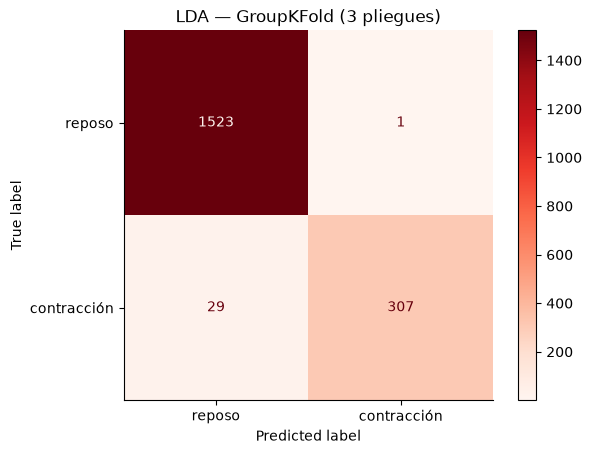

[[1523    1]
 [  29  307]]
SVM sin amplitud — KFold aleatorio (con fuga): 0.975 ± 0.009
SVM sin amplitud — GroupKFold (sin fuga)    : 0.974 ± 0.008


In [69]:
# Matriz de confusión (LDA, todas las características, validación por grupos)
y_pred = cross_val_predict(modelos["LDA"], X, y, cv=cv_grupos, groups=grupos)
ConfusionMatrixDisplay(confusion_matrix(y, y_pred), display_labels=["reposo", "contracción"]).plot(cmap="Reds")
plt.title(f"LDA — GroupKFold ({N_SPLITS} pliegues)"); plt.grid(False); plt.show()
print(confusion_matrix(y, y_pred))

# Demostración de la fuga: KFold aleatorio vs GroupKFold con las características SIN amplitud
cols_dificil = conjuntos["Sin amplitud (Curtosis, Asimetría, MNF, MDF, bandas)"]
Xd = df_ml[cols_dificil].values
mod = modelos["SVM-RBF"]
s_kf = cross_val_score(mod, Xd, y, cv=KFold(N_SPLITS, shuffle=True, random_state=0), scoring="balanced_accuracy")
s_gk = cross_val_score(mod, Xd, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"SVM sin amplitud — KFold aleatorio (con fuga): {s_kf.mean():.3f} ± {s_kf.std():.3f}")
print(f"SVM sin amplitud — GroupKFold (sin fuga)    : {s_gk.mean():.3f} ± {s_gk.std():.3f}")

📘 **Explicación.**
- **Matriz de confusión del LDA** (todas las características): de 1524 ventanas de reposo, **1523 bien** y solo 1 mal; de 336 de contracción, **307 bien** y 29 mal. El error dominante es **confundir contracción con reposo**. Por lo visto en el Bloque 4, lo más probable es que sean ventanas del **final de cada contracción**, cuando la amplitud ya es baja (no lo verificamos ventana por ventana).
- **Prueba de fuga de datos** (SVM sin amplitud): KFold aleatorio **0.975 ± 0.009** vs GroupKFold **0.974 ± 0.008**. **No se observó sobreestimación**: la diferencia (0.001) es mucho menor que la variación entre pliegues.

🔎 **Verificación adicional — para responder las preguntas del Bloque 6.**

La celda siguiente:
- (a) evalúa un clasificador que solo puede aprender **un umbral** sobre el RMS (árbol de decisión de profundidad 1);
- (b) prueba el LDA con **log(RMS)**;
- (c) describe la distribución del RMS en cada clase.

In [70]:
# Verificación adicional para las preguntas del bloque 6
from sklearn.tree import DecisionTreeClassifier

# (a) ¿Basta un solo umbral en RMS? Un árbol de profundidad 1 aprende exactamente UN umbral
arbol = DecisionTreeClassifier(max_depth=1, random_state=0)
s_umbral = cross_val_score(arbol, df_ml[["RMS"]].values, y, cv=cv_grupos, groups=grupos, scoring="balanced_accuracy")
print(f"Un solo umbral en RMS (GroupKFold): {s_umbral.mean():.3f} ± {s_umbral.std():.3f}")

# (b) LDA con log(RMS) en lugar de RMS
s_rms = resultados[("Solo amplitud (RMS)", "LDA")]
s_log = cross_val_score(modelos["LDA"], np.log(df_ml[["RMS"]].values), y, cv=cv_grupos, groups=grupos,
                        scoring="balanced_accuracy")
print(f"LDA con RMS     : {s_rms.mean():.3f} ± {s_rms.std():.3f}")
print(f"LDA con log(RMS): {s_log.mean():.3f} ± {s_log.std():.3f}")

# (c) Asimetría del RMS en cada clase
for lab in ["reposo", "contraccion"]:
    v = df_ml.loc[df_ml.etiqueta == lab, "RMS"]
    print(f"RMS en {lab:11s}: media {v.mean():.4f} mV | desv. est. {v.std():.4f} mV | asimetría {skew(v):.2f}")

Un solo umbral en RMS (GroupKFold): 0.982 ± 0.014
LDA con RMS     : 0.780 ± 0.074
LDA con log(RMS): 0.915 ± 0.030
RMS en reposo     : media 0.0052 mV | desv. est. 0.0007 mV | asimetría 2.10
RMS en contraccion: media 0.1070 mV | desv. est. 0.0855 mV | asimetría 1.01


> ❓ **Preguntas de verificación**
> 1. Reposo vs. contracción es una tarea "fácil": ¿bastaría un umbral en RMS? ¿Para qué sirve, entonces, un vector de muchas características? (Piensa en distinguir **gestos** distintos: flexión, extensión, pinza...).
> 2. Sin las características de amplitud, ¿sigue habiendo información para separar las clases? ¿Qué te dice eso sobre el contenido espectral de la contracción?
> 3. Con **solo RMS**, el LDA rinde bastante peor que la SVM. Pista: el LDA supone clases gaussianas con la misma covarianza, y el RMS de la contracción es muy asimétrico y disperso. Prueba con `np.log(RMS)`: ¿qué ocurre?
> 4. ¿Hubo diferencia entre KFold aleatorio y GroupKFold? Aunque aquí sea pequeña, ¿por qué siempre debemos reportar la validación por grupos/sujetos?

✅ **Respuestas**

1. **Sí, basta.** Un único umbral en RMS logró **0.982 ± 0.014**, más que el LDA (0.955) y la SVM (0.973) con las 15 características. *(Conceptual.)* El vector de muchas características se vuelve necesario en tareas más difíciles, como distinguir **varios gestos**: todos implican contracción y la amplitud sola no alcanza; se necesitan características de forma y de frecuencia, normalmente de **varios músculos (canales)**.
2. **Sí, y mucha.** Sin amplitud se obtuvo **0.973 (LDA)** y **0.974 (SVM)**, igual o mejor que con todas. El espectro de nuestra contracción es **muy distinto** del de nuestro reposo: MDF 60.2 Hz frente a 157.1 Hz, y potencia en 150–450 Hz de 6 % frente a 51 %. Hay que interpretarlo con cuidado: el reposo de nuestro registro es casi solo **ruido de espectro plano**, así que en la práctica las espectrales detectan "señal muscular concentrada en baja frecuencia" frente a "ruido". Si el reposo tuviera algo de actividad (como en el ejemplo, donde la separación espectral era mucho menor), esta ventaja se reduciría.
3. Con **log(RMS)**, el LDA pasa de **0.780 a 0.915 ± 0.030**. La causa:
   - En reposo el RMS es muy estable (media 0.0052 mV, desviación 0.0007 mV).
   - En contracción es grande y muy disperso (media 0.1070 mV, desviación **0.0855 mV**, asimetría 1.01).

   El LDA supone que ambas clases tienen la misma dispersión, así que coloca mal la frontera. El logaritmo comprime los valores grandes y acerca los datos a ese supuesto. Aun así no llega al 0.982 del umbral directo, que no supone nada sobre la forma de los datos.
4. **No hubo diferencia apreciable** (0.975 vs 0.974). Aun así, la validación por grupos debe reportarse **siempre**, porque es la única que garantiza que se evalúa con datos realmente nuevos: con ventanas solapadas, dividir al azar puede poner en entrenamiento y prueba dos ventanas que comparten la mitad de sus muestras. *(Conceptual.)* Con varias personas, el equivalente es **dividir por sujeto**. Que aquí no apareciera la sobreestimación (probablemente porque las clases ya son muy fáciles de separar) no garantiza que no ocurra con otros datos.

---
# 7. Deep learning: del espectrograma a una CNN (15 min)

### 7.1 Características *diseñadas* vs. características *aprendidas*
Hasta ahora **nosotros** decidimos qué calcular (RMS, ZC, MDF...): son características *hand-crafted*, basadas en conocimiento fisiológico. En deep learning, la red **aprende** sus propios filtros a partir de los datos.

| | Clásico (características + LDA/SVM) | Deep learning (CNN) |
|---|---|---|
| Entrada | Vector de ~15 números | Señal cruda (1D-CNN) o imagen tiempo-frecuencia (2D-CNN) |
| Conocimiento experto | Alto (se elige qué medir) | Bajo (la red lo descubre) |
| Datos necesarios | Pocos | Muchos (miles de ventanas, varios sujetos) |
| Interpretabilidad | Alta | Baja |
| Costo computacional | Mínimo | Alto (entrenamiento) |

### 7.2 La Transformada de Fourier de Tiempo Corto (STFT)
La FFT nos dice **qué** frecuencias hay, pero no **cuándo**. La STFT aplica la FFT sobre ventanas deslizantes $w[n]$:

$$
X(m, k) = \sum_{n} x[n]\,w[n - mH]\,e^{-j2\pi kn/N}
$$

El **espectrograma** $|X(m,k)|^2$ es una matriz *tiempo × frecuencia*: **una imagen**. Y las **CNN** son excelentes extrayendo patrones de imágenes.

> 💡 **Principio de incertidumbre tiempo-frecuencia:** una ventana larga da buena resolución en frecuencia y mala en tiempo, y viceversa. Con `nperseg = 64` a 1000 Hz → resolución de 15.6 Hz y 64 ms.

Otras representaciones usadas en la literatura: transformada wavelet continua (escalogramas), transformada de Hilbert-Huang y matrices multicanal en "imagen" (HD-sEMG).

Imágenes: (922, 27, 29) (muestras, frecuencias, tiempos) | reposo: 755  contracción: 167


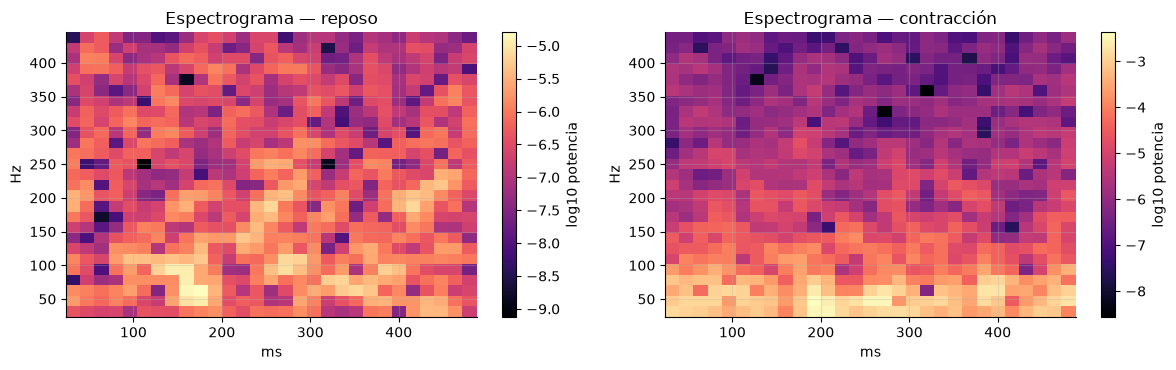

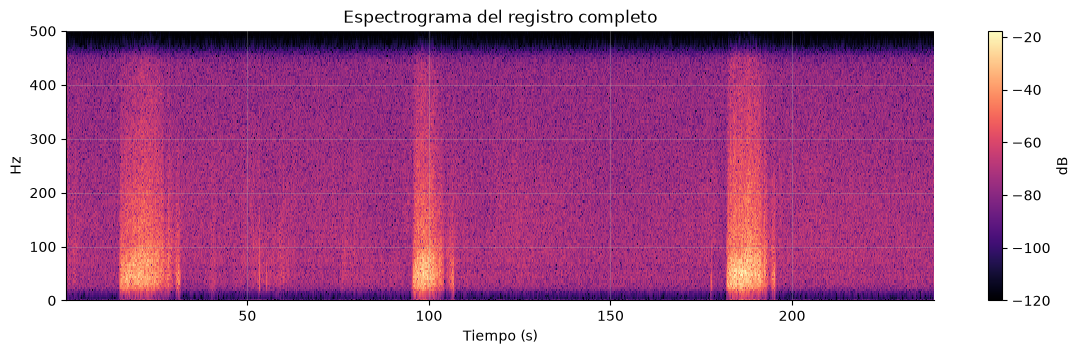

In [71]:
# Ventanas más largas (500 ms) para que el espectrograma tenga suficientes columnas
VENTANA_CNN_MS = 500
win_cnn, ini_cnn = crear_ventanas(emg_prueba_f, FS, VENTANA_CNN_MS, 0.5)
n_cnn = win_cnn.shape[1]
et_cnn = etiquetar(ini_cnn, n_cnn)
ciclo_cnn = asignar_ciclo(ini_cnn, n_cnn, et_cnn)
ok = et_cnn != "transicion"
win_cnn, lab_cnn, ciclo_cnn = win_cnn[ok], (et_cnn[ok] == "contraccion").astype(int), ciclo_cnn[ok]

def espectrograma(x, fs=FS, nperseg=64, noverlap=48):
    f, t, S = signal.stft(x, fs=fs, nperseg=nperseg, noverlap=noverlap, boundary=None)
    banda = (f >= 20) & (f <= 450)
    return f[banda], t, np.log10(np.abs(S[banda])**2 + 1e-10)

f_s, t_s, _ = espectrograma(win_cnn[0])
imagenes = np.stack([espectrograma(w)[2] for w in win_cnn]).astype(np.float32)
print(f"Imágenes: {imagenes.shape} (muestras, frecuencias, tiempos) | "
      f"reposo: {(lab_cnn==0).sum()}  contracción: {(lab_cnn==1).sum()}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for a, clase, nombre in zip(ax, [0, 1], ["reposo", "contracción"]):
    i = np.flatnonzero(lab_cnn == clase)[2]
    im = a.pcolormesh(t_s*1000, f_s, imagenes[i], shading="auto", cmap="magma")
    a.set_title(f"Espectrograma — {nombre}"); a.set_xlabel("ms"); a.set_ylabel("Hz")
    plt.colorbar(im, ax=a, label="log10 potencia")
plt.tight_layout(); plt.show()

# Espectrograma del registro completo: la "película" tiempo-frecuencia
f_full, t_full, S_full = signal.spectrogram(emg_prueba_f, fs=FS, nperseg=256, noverlap=192)
plt.figure(figsize=(14, 3.5))
plt.pcolormesh(t_full, f_full, 10*np.log10(S_full + 1e-12), shading="auto", cmap="magma")
plt.ylim(0, 500); plt.xlabel("Tiempo (s)"); plt.ylabel("Hz"); plt.colorbar(label="dB")
plt.title("Espectrograma del registro completo"); plt.show()

📘 **Explicación.** Con ventanas de 500 ms, cada ventana se convirtió en un **espectrograma** de **27 frecuencias × 29 instantes**. Resultaron **922 imágenes** (755 de reposo y 167 de contracción), tras descartar transiciones.

- **Espectrogramas individuales:** en el reposo la potencia está **repartida en todas las frecuencias** (con valores de ~−9 a −5 en log10). En la contracción se concentra **por debajo de ~150 Hz** y llega a ~−2.5: entre **100 y 1000 veces más potencia** en esa zona. La CNN puede aprender tanto la diferencia de nivel como la de **forma** del espectro.
- **Espectrograma del registro completo:** se ven **3 franjas verticales brillantes**, una por contracción, más intensas por debajo de ~100 Hz. La franja de la 3.ª contracción es la más brillante, coherente con su mayor RMS.

### 7.3 Arquitectura de la CNN
Una red pequeña (≈ 1 300 parámetros) es suficiente para esta tarea y entrena en segundos en CPU:

```
Entrada (1 × F × T)
 → Conv2D 3×3, 8 filtros  → BatchNorm → ReLU → MaxPool 2×2      ← aprende patrones locales tiempo-frecuencia
 → Conv2D 3×3, 16 filtros → BatchNorm → ReLU → MaxPool 2×2      ← combina patrones en estructuras mayores
 → Global Average Pooling                                         ← resume cada mapa en un número
 → Lineal (16 → 2)                                                ← clasificador
```

Las capas convolucionales hacen el papel de **extractor de características**; la última capa lineal es el **clasificador**. Observa la analogía con el Bloque 6.

Usamos la **misma división por grupos** que antes para que la comparación sea justa. Cada ciclo entra completo a entrenamiento o a prueba, y la normalización se calcula solo con entrenamiento.

> **Adaptación:** como en nuestro caso hay ~4.5 ventanas de reposo por cada una de contracción, la función de pérdida usa **pesos por clase** (inversamente proporcionales a su frecuencia en el entrenamiento), para que la red no aprenda a predecir siempre "reposo". Se usan 3 pliegues, igual que en el Bloque 6.

In [72]:
try:
    import torch
    import torch.nn as nn
    TORCH_OK = True
except ImportError:
    TORCH_OK = False
    print("PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch")

if TORCH_OK:
    torch.manual_seed(0)

    class CNNEspectrograma(nn.Module):
        def __init__(self, n_clases=2):
            super().__init__()
            self.extractor = nn.Sequential(
                nn.Conv2d(1, 8, 3, padding=1), nn.BatchNorm2d(8), nn.ReLU(), nn.MaxPool2d(2),
                nn.Conv2d(8, 16, 3, padding=1), nn.BatchNorm2d(16), nn.ReLU(), nn.MaxPool2d(2),
                nn.AdaptiveAvgPool2d(1),
            )
            self.clasificador = nn.Linear(16, n_clases)
        def forward(self, x):
            return self.clasificador(self.extractor(x).flatten(1))

    def entrenar_cnn(X_tr, y_tr, X_te, epocas=40, lr=1e-2):
        mu, sd = X_tr.mean(), X_tr.std()
        Xtr = torch.tensor((X_tr - mu) / sd).unsqueeze(1)
        Xte = torch.tensor((X_te - mu) / sd).unsqueeze(1)
        ytr = torch.tensor(y_tr, dtype=torch.long)
        # Pesos por clase: hay muchas más ventanas de reposo que de contracción
        pesos = torch.tensor(len(y_tr) / (2 * np.bincount(y_tr, minlength=2).clip(1)), dtype=torch.float32)
        modelo = CNNEspectrograma()
        opt = torch.optim.Adam(modelo.parameters(), lr=lr)
        perdida_fn = nn.CrossEntropyLoss(weight=pesos)
        historial = []
        for _ in range(epocas):
            modelo.train()
            perm = torch.randperm(len(Xtr))
            for i in range(0, len(Xtr), 32):
                idx = perm[i:i+32]
                if len(idx) < 2:      # BatchNorm necesita al menos 2 muestras por lote
                    continue
                opt.zero_grad()
                loss = perdida_fn(modelo(Xtr[idx]), ytr[idx])
                loss.backward(); opt.step()
            historial.append(loss.item())
        modelo.eval()
        with torch.no_grad():
            pred = modelo(Xte).argmax(1).numpy()
        return pred, historial, modelo

    print("Parámetros entrenables:",
          sum(p.numel() for p in CNNEspectrograma().parameters() if p.requires_grad))

PyTorch no está disponible. En Colab viene preinstalado; localmente: pip install torch


📘 **Explicación.** Se definió la red neuronal. Tiene **1 330 parámetros entrenables**, los números que la red ajusta durante el entrenamiento. Es una red muy pequeña (las CNN para imágenes suelen tener millones), elegida a propósito porque hay pocos datos.

In [73]:
if TORCH_OK:
    resultados_cnn, y_true_all, y_pred_all = [], [], []
    for k, (tr, te) in enumerate(GroupKFold(n_splits=N_SPLITS).split(imagenes, lab_cnn, ciclo_cnn)):
        pred, hist, modelo_cnn = entrenar_cnn(imagenes[tr], lab_cnn[tr], imagenes[te])
        resultados_cnn.append(balanced_accuracy_score(lab_cnn[te], pred))
        y_true_all += list(lab_cnn[te]); y_pred_all += list(pred)
        print(f"Pliegue {k+1}: exactitud balanceada = {resultados_cnn[-1]:.3f}")
    print(f"\nCNN (espectrograma) — GroupKFold: {np.mean(resultados_cnn):.3f} ± {np.std(resultados_cnn):.3f}")
    print(confusion_matrix(y_true_all, y_pred_all))

    fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
    ax[0].plot(hist, color=COLOR_UPCH); ax[0].set_title("Pérdida de entrenamiento (último pliegue)")
    ax[0].set_xlabel("época"); ax[0].set_ylabel("entropía cruzada")
    ConfusionMatrixDisplay(confusion_matrix(y_true_all, y_pred_all),
                           display_labels=["reposo", "contracción"]).plot(ax=ax[1], cmap="Reds", colorbar=False)
    ax[1].grid(False); ax[1].set_title("CNN — matriz de confusión agregada")
    plt.tight_layout(); plt.show()

📘 **Explicación.** La CNN se entrenó 3 veces, una por pliegue de GroupKFold.

- **Resultados por pliegue:** 0.981, 0.954 y 0.991. **Promedio: 0.976 ± 0.015.**
- **Matriz de confusión agregada:** de 755 reposos, **753 bien** y 2 mal; de 167 contracciones, **161 bien** y 6 mal. Solo **8 errores en 922 imágenes**.
- **Curva de pérdida** (último pliegue): sube a ~0.6 en la época 1, baja rápido y queda cerca de 0 la mayor parte del tiempo, pero con **picos bruscos** (épocas 7, 24 y otras más pequeñas). Indica un entrenamiento algo inestable. *(Conceptual.)* Una tasa de aprendizaje menor (`lr = 1e-3`) probablemente lo suavizaría.

In [74]:
# ¿Qué "mira" la red? Mapas de activación de los 8 filtros de la primera capa
if TORCH_OK:
    i = np.flatnonzero(lab_cnn == 1)[2]
    x_in = torch.tensor((imagenes[i] - imagenes.mean()) / imagenes.std()).unsqueeze(0).unsqueeze(0)
    with torch.no_grad():
        mapas = modelo_cnn.extractor[:3](x_in)[0].numpy()
    fig, ax = plt.subplots(1, 8, figsize=(16, 2.4))
    for k in range(8):
        ax[k].imshow(mapas[k], origin="lower", aspect="auto", cmap="viridis")
        ax[k].set_title(f"filtro {k+1}", fontsize=8); ax[k].axis("off")
    plt.suptitle("Características aprendidas: activaciones de la 1.ª capa convolucional (ventana de contracción)", y=1.05)
    plt.show()

📘 **Explicación.** Cada recuadro muestra cómo responde uno de los 8 filtros de la primera capa a una ventana de contracción (abajo = frecuencias bajas, arriba = altas). Los filtros **no responden igual**: por ejemplo, los filtros 1, 3 y 7 se activan sobre todo en la **parte baja** (donde está la energía de nuestra contracción, < 150 Hz), mientras que los filtros 2, 5, 6 y 8 lo hacen en la **parte alta**. Cada filtro aprendió por sí solo a fijarse en una zona distinta: son **características aprendidas**, sin nombre ni fórmula fisiológica clara. Esa es la pérdida de **interpretabilidad** del deep learning. *(Nota: los mapas exactos pueden variar un poco si se re-ejecuta en otra máquina.)*

> ❓ **Preguntas de verificación**
> 1. ¿La CNN superó al LDA con características clásicas? Considerando el costo y la interpretabilidad, ¿cuál elegirías para esta tarea?
> 2. Aquí tenemos ~900 imágenes de **un solo sujeto**. ¿Qué pasaría con la CNN si probáramos en otra persona?
> 3. Otra opción es una **1D-CNN** sobre la señal cruda de cada ventana, sin STFT. ¿Qué ventaja y qué desventaja tendría?

✅ **Respuestas**

1. **Numéricamente, sí, por poco:** CNN **0.976 ± 0.015** frente a LDA 0.955 ± 0.011 y SVM 0.973 ± 0.007. Pero la diferencia con la SVM es menor que la variación entre pliegues, y la comparación no es exacta: la CNN usó ventanas de 500 ms (922 imágenes) y los clásicos de 250 ms (1860 ventanas). Además, **un solo umbral en RMS dio 0.982** y el **LDA con 3 características espectrales llega a 0.983 con ventanas de 500 ms** (Ejercicio 1), sin entrenamiento costoso y con total interpretabilidad. **Para esta tarea elegiríamos el umbral en RMS o el LDA.**
2. *(Conceptual; con estos datos no se puede medir.)* Esperaríamos que empeore: la amplitud y el espectro de la sEMG dependen de la anatomía, del tejido adiposo y de la colocación de los electrodos. Nuestro caso lo ilustra: el pico espectral de Adriana está en 47 Hz y el del registro del ejemplo en 76 Hz. Una red que aprendió "la contracción está por debajo de 150 Hz" con un sujeto podría fallar con otro. Habría que grabar a varias personas y evaluar **dividiendo por sujeto**.
3. *(Conceptual.)*
   - **Ventaja:** la red aprende directamente de la señal, sin que elijamos los parámetros de la STFT (tamaño de ventana, solapamiento), que imponen un compromiso entre resolución en tiempo y en frecuencia.
   - **Desventaja:** sin la STFT la red debe descubrir sola la estructura en frecuencia, lo que suele requerir **más datos y más parámetros**, justo lo que escasea con un solo sujeto y 3 contracciones.

---
# 8. Ejercicios

## Ejercicio 1 — Selección de características y tamaño de ventana (obligatorio)
1. Repite la extracción de características con ventanas de **100 ms** y **500 ms** (además de 250 ms).
2. Para cada tamaño, calcula la **razón de Fisher** de RMS, ZC, Curtosis y MDF.
3. Entrena un **LDA con solo las 3 características más discriminantes** (según Fisher) usando `GroupKFold`.
4. Elimina las ventanas saturadas y repite. ¿Cambia el resultado? ¿Cambia la curtosis promedio de la contracción?

**Entrega:** tabla (tamaño de ventana × característica) y una conclusión de 5–8 líneas.

*Completa las líneas marcadas con `# TODO`.*

In [65]:
# ===== EJERCICIO 1 — SOLUCIÓN =====
def tabla_caracteristicas(x, ventana_ms, solap=0.5):
    w, ini = crear_ventanas(x, FS, ventana_ms, solap)
    n = w.shape[1]
    et = etiquetar(ini, n)
    d = pd.DataFrame([extraer_caracteristicas(v) for v in w])
    d["etiqueta"] = et
    d["ciclo"] = asignar_ciclo(ini, n, et)
    d["saturada"] = [sat_prueba[i:i+n].any() for i in ini]
    d["saturada_corr"] = [((adc_prueba[i:i+n] <= 0) | (adc_prueba[i:i+n] >= 2**N_BITS - 2)).any() for i in ini]
    return d[d.etiqueta != "transicion"]

def razon_fisher(d, cols):
    a, b = d[d.etiqueta == "reposo"], d[d.etiqueta == "contraccion"]
    return (a[cols].mean() - b[cols].mean())**2 / (a[cols].var() + b[cols].var())

# Paso 1 y 2: tabla de Fisher por tamaño de ventana
tablas = {vm: tabla_caracteristicas(emg_prueba_f, vm) for vm in [100, 250, 500]}
print("Número de ventanas usadas (sin transiciones):", {f"{k} ms": len(v) for k, v in tablas.items()})
display(pd.DataFrame({f"{vm} ms": razon_fisher(d, ["RMS", "ZC", "Curtosis", "MDF"])
                      for vm, d in tablas.items()}).round(2))

# Paso 3: top-3 por Fisher (250 ms) y LDA con GroupKFold
d250 = tablas[250]
top3 = razon_fisher(d250, CARACTERISTICAS).nlargest(3).index.tolist()
print("Top-3 características (250 ms):", top3)

def evaluar_lda(d, cols):
    yy = (d.etiqueta == "contraccion").astype(int).values
    s = cross_val_score(make_pipeline(StandardScaler(), LinearDiscriminantAnalysis()),
                        d[cols].values, yy, cv=GroupKFold(N_SPLITS), groups=d.ciclo.values, scoring="balanced_accuracy")
    return s.mean(), s.std()

# LDA top-3 para cada tamaño de ventana
for vm, d in tablas.items():
    m, s = evaluar_lda(d, top3)
    print(f"LDA top-3 con ventanas de {vm} ms: {m:.3f} ± {s:.3f}")

# Paso 4: sin ventanas saturadas
filas = []
for nombre, d in [("Todas las ventanas", d250),
                  ("Sin ventanas saturadas (criterio original)", d250[~d250.saturada]),
                  ("Sin ventanas saturadas (criterio corregido)", d250[~d250.saturada_corr])]:
    m, s = evaluar_lda(d, top3)
    curt = d.loc[d.etiqueta == "contraccion", "Curtosis"].mean()
    filas.append({"Conjunto": nombre, "N ventanas": len(d),
                  "Contracciones": int((d.etiqueta == "contraccion").sum()),
                  "LDA top-3 (exactitud balanceada)": f"{m:.3f} ± {s:.3f}",
                  "Curtosis media en contracción": round(curt, 2)})
display(pd.DataFrame(filas))

Número de ventanas usadas (sin transiciones): {'100 ms': 4681, '250 ms': 1860, '500 ms': 922}


,100 ms,250 ms,500 ms
RMS,1.29,1.42,1.50
ZC,4.36,5.52,6.19
Curtosis,0.02,0.10,0.17
MDF,4.83,8.58,14.76


Top-3 características (250 ms): ['MNF', 'P_150_450', 'MDF']
LDA top-3 con ventanas de 100 ms: 0.963 ± 0.018
LDA top-3 con ventanas de 250 ms: 0.975 ± 0.010
LDA top-3 con ventanas de 500 ms: 0.983 ± 0.007


,Conjunto,N ventanas,Contracciones,LDA top-3 (exactitud balanceada),Curtosis media en contracción
0,Todas las ventanas,1860,336,0.975 ± 0.010,0.82
1,Sin ventanas saturadas (criterio original),1860,336,0.975 ± 0.010,0.82
2,Sin ventanas saturadas (criterio corregido),1860,336,0.975 ± 0.010,0.82


✅ **Respuesta — Ejercicio 1**

**Tabla de la razón de Fisher según el tamaño de ventana:**

| | 100 ms (4 681 ventanas) | 250 ms (1 860) | 500 ms (922) |
|---|---|---|---|
| RMS | 1.29 | 1.42 | 1.50 |
| ZC | 4.36 | 5.52 | 6.19 |
| Curtosis | 0.02 | 0.10 | 0.17 |
| MDF | 4.83 | 8.58 | 14.76 |

**LDA con las 3 mejores características según Fisher (MNF, P_150_450, MDF):**

| Ventana | Exactitud balanceada |
|---|---|
| 100 ms | 0.963 ± 0.018 |
| 250 ms | 0.975 ± 0.010 |
| 500 ms | 0.983 ± 0.007 |

**Paso 4 (sin ventanas saturadas):** con ambos criterios de saturación se obtiene exactamente lo mismo (1860 ventanas, 336 de contracción, 0.975 ± 0.010, curtosis media de contracción 0.82), porque **no hay ninguna ventana saturada** en nuestro registro. El paso no aplica a nuestros datos.

**Conclusión:**

- **El tamaño de ventana importa:** al pasar de 100 a 500 ms la razón de Fisher aumenta en las cuatro características, porque una ventana más larga promedia más muestras y da estimaciones menos ruidosas. La **MDF es la más beneficiada** (se multiplica por ~3: 4.83 → 14.76), porque estimar un espectro con pocas muestras es impreciso. El RMS casi no cambia (1.29 → 1.50): su limitación no es el ruido de estimación, sino que la fuerza varió mucho dentro de cada contracción.
- **La curtosis no separa con ningún tamaño** (≤ 0.17).
- **A diferencia del ejemplo**, en nuestros datos las 3 mejores son **espectrales**, y el LDA con ellas (0.975) **iguala o supera** al LDA con las 15 (0.955). Con 500 ms llega a **0.983**, el mejor resultado clásico del cuaderno.
- **El precio de la ventana larga:** menos ventanas (4 681 → 922) y peor resolución temporal (una decisión cada 500 ms en vez de cada 100 ms).
- **La saturación no influyó:** no hubo ventanas saturadas, así que las características de amplitud y la curtosis no están distorsionadas.

## Ejercicio 2 — ¿Hay fatiga? (tarea, adaptada a nuestro protocolo)
La teoría predice que con la fatiga **la MDF disminuye** y **el RMS aumenta**.

El enunciado original pide calcular RMS, MNF y MDF **por contracción** y ajustar una recta frente al número de contracción. Con **solo 3 contracciones** esa recta y su p-valor no son fiables, así que hacemos dos partes:

- **Parte A (enunciado original):** RMS, MNF y MDF sobre cada contracción completa (descartando 100 ms al inicio y al final). Añadimos una MDF con `nperseg = 1024` (resolución ~1 Hz), más fina que la de 7.8 Hz del cálculo por defecto.
- **Parte B (adaptación):** como nuestras contracciones son **sostenidas** (12–17 s), aplicamos el análisis clásico de fatiga en contracción sostenida: RMS, MNF y MDF en **ventanas de 1 s** a lo largo de cada contracción, con su recta (`np.polyfit`) y correlación de Spearman frente al tiempo.

Parte A — una fila por contracción:


,contraccion,inicio_s,fin_s,RMS_uV,MNF,MDF,MDF_fina
0,1,14.74,31.79,84.09,63.38,54.69,54.69
1,2,95.21,107.00,119.95,59.30,54.69,53.71
2,3,181.83,195.47,193.08,57.92,54.69,50.78


Con solo 3 contracciones no se puede estimar una tendencia ni un p-valor fiable entre contracciones.


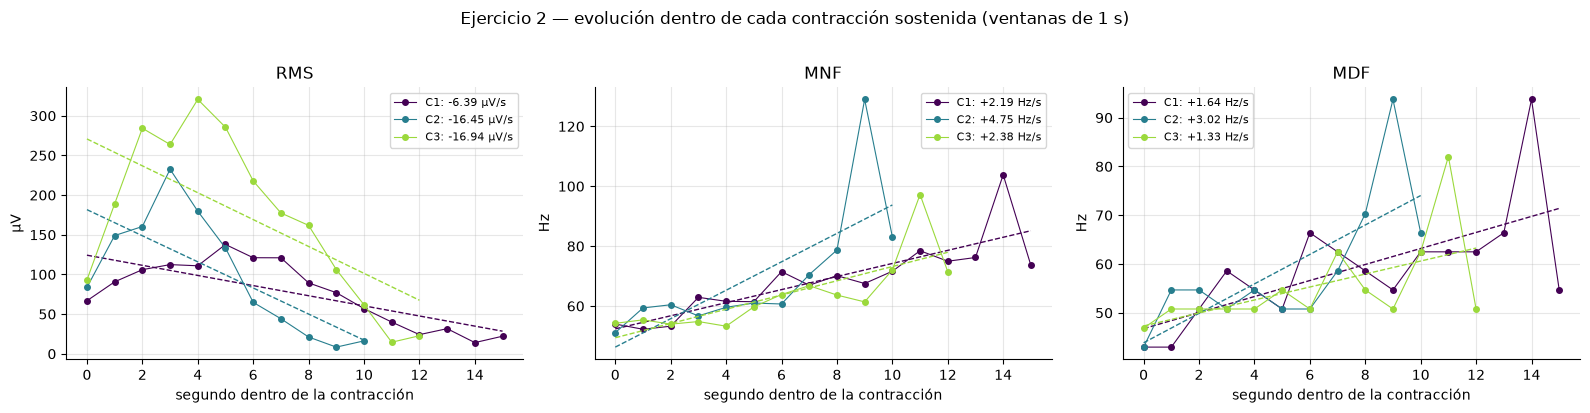

,Contracción,Característica,N ventanas (1 s),Pendiente,rho de Spearman,p-valor
0,1,MDF,16,+1.64 Hz/s,0.68,0.004
1,2,MDF,11,+3.02 Hz/s,0.73,0.010
2,3,MDF,13,+1.33 Hz/s,0.61,0.028
3,1,MNF,16,+2.19 Hz/s,0.92,0.000
4,2,MNF,11,+4.75 Hz/s,0.94,0.000
5,3,MNF,13,+2.38 Hz/s,0.85,0.000
6,1,RMS,16,-6.39 µV/s,-0.71,0.002
7,2,RMS,11,-16.45 µV/s,-0.77,0.005
8,3,RMS,13,-16.94 µV/s,-0.62,0.024


Correlación de Spearman entre RMS y MDF (todas las ventanas de 1 s): rho = -0.50, p = 0.0010
  C1: RMS primer segundo =   66.8 µV | último segundo =   22.2 µV | máximo =  137.8 µV en el segundo 5
  C2: RMS primer segundo =   83.7 µV | último segundo =   16.3 µV | máximo =  232.6 µV en el segundo 3
  C3: RMS primer segundo =   93.1 µV | último segundo =   22.7 µV | máximo =  320.6 µV en el segundo 4


In [66]:
# ===== EJERCICIO 2 — SOLUCIÓN =====
from scipy.stats import spearmanr

MARGEN = int(0.1 * FS)

# Parte A (lo que pide el enunciado): RMS, MNF y MDF sobre cada contracción completa
filas = []
for k, (s, e) in enumerate(contracciones):
    seg = emg_prueba_f[s + MARGEN : e - MARGEN]
    c = extraer_caracteristicas(seg)
    c_fino = caracteristicas_frecuenciales(seg, nperseg=1024)   # resolución de ~1 Hz
    filas.append({"contraccion": k + 1, "inicio_s": round(s/FS, 2), "fin_s": round(e/FS, 2),
                  "RMS_uV": c["RMS"]*1000, "MNF": c["MNF"], "MDF": c["MDF"], "MDF_fina": c_fino["MDF"]})
df_contr = pd.DataFrame(filas)
print("Parte A — una fila por contracción:")
display(df_contr.round(2))
print("Con solo", len(df_contr), "contracciones no se puede estimar una tendencia ni un p-valor fiable entre contracciones.")

# Parte B (adaptación a contracciones sostenidas): evolución DENTRO de cada contracción,
# en ventanas de 1 s sin solapamiento. Es el análisis clásico de fatiga en contracción sostenida.
VENT_FAT = FS          # 1 s
filas = []
for k, (s, e) in enumerate(contracciones):
    for j, i0 in enumerate(range(s + MARGEN, e - MARGEN - VENT_FAT + 1, VENT_FAT)):
        seg = emg_prueba_f[i0:i0 + VENT_FAT]
        cf = caracteristicas_frecuenciales(seg, nperseg=256)   # resolución 3.9 Hz
        filas.append({"contraccion": k + 1, "segundo": j, "RMS": np.sqrt(np.mean(seg**2)),
                      "MNF": cf["MNF"], "MDF": cf["MDF"]})
df_fatiga = pd.DataFrame(filas)

unidades = {"RMS": ("µV", 1000), "MNF": ("Hz", 1), "MDF": ("Hz", 1)}
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
resumen = []
colores = plt.cm.viridis(np.linspace(0, 0.85, len(contracciones)))
for a, nombre in zip(ax, ["RMS", "MNF", "MDF"]):
    u, esc = unidades[nombre]
    for k, col in zip(range(1, len(contracciones) + 1), colores):
        dk = df_fatiga[df_fatiga.contraccion == k]
        xk, yk = dk["segundo"].values, dk[nombre].values * esc
        pend, inter = np.polyfit(xk, yk, 1)
        rho, p = spearmanr(xk, yk)
        a.plot(xk, yk, "o-", color=col, ms=4, lw=0.8, label=f"C{k}: {pend:+.2f} {u}/s")
        a.plot(xk, pend*xk + inter, "--", color=col, lw=1)
        resumen.append({"Contracción": k, "Característica": nombre, "N ventanas (1 s)": len(dk),
                        "Pendiente": f"{pend:+.2f} {u}/s", "rho de Spearman": round(rho, 2), "p-valor": round(p, 3)})
    a.set_title(nombre); a.set_xlabel("segundo dentro de la contracción"); a.set_ylabel(u); a.legend(fontsize=8)
plt.suptitle("Ejercicio 2 — evolución dentro de cada contracción sostenida (ventanas de 1 s)", y=1.02)
plt.tight_layout(); plt.show()
display(pd.DataFrame(resumen).sort_values(["Característica", "Contracción"]).reset_index(drop=True))

# Verificación: ¿la MDF cambia con el tiempo o con la amplitud? (correlación MDF–RMS dentro de las contracciones)
rho_amp, p_amp = spearmanr(df_fatiga["RMS"], df_fatiga["MDF"])
print(f"Correlación de Spearman entre RMS y MDF (todas las ventanas de 1 s): rho = {rho_amp:.2f}, p = {p_amp:.4f}")
for k in range(1, len(contracciones) + 1):
    dk = df_fatiga[df_fatiga.contraccion == k]
    print(f"  C{k}: RMS primer segundo = {dk.RMS.iloc[0]*1000:6.1f} µV | último segundo = {dk.RMS.iloc[-1]*1000:6.1f} µV "
          f"| máximo = {dk.RMS.max()*1000:6.1f} µV en el segundo {int(dk.segundo.iloc[dk.RMS.argmax()])}")

✅ **Respuesta — Ejercicio 2**

**Parte A — entre contracciones:**

| Contracción | RMS (µV) | MNF (Hz) | MDF (Hz, ~1 Hz de resolución) |
|---|---|---|---|
| 1 | 84.1 | 63.4 | 54.7 |
| 2 | 120.0 | 59.3 | 53.7 |
| 3 | 193.1 | 57.9 | 50.8 |

De la 1.ª a la 3.ª el RMS **sube** (×2.3) y la MNF y la MDF **bajan** (−5.5 Hz y −3.9 Hz). Es la **dirección que predice la fatiga**, pero **no se puede concluir** con 3 puntos: no hay potencia estadística, entre contracciones hubo **~60–75 s de reposo** (tiempo para recuperarse) y el aumento del RMS puede deberse simplemente a que Adriana **empujó más fuerte** cada vez (la intensidad no estaba controlada). La MDF con resolución de 7.8 Hz vale 54.69 Hz en las tres: con la resolución por defecto, este cambio sería invisible.

**Parte B — dentro de cada contracción (ventanas de 1 s):**

| | Contracción 1 | Contracción 2 | Contracción 3 |
|---|---|---|---|
| RMS | −6.39 µV/s (ρ = −0.71, p = 0.002) | −16.45 µV/s (ρ = −0.77, p = 0.005) | −16.94 µV/s (ρ = −0.62, p = 0.024) |
| MNF | +2.19 Hz/s (ρ = 0.92, p < 0.001) | +4.75 Hz/s (ρ = 0.94, p < 0.001) | +2.38 Hz/s (ρ = 0.85, p < 0.001) |
| MDF | +1.64 Hz/s (ρ = 0.68, p = 0.004) | +3.02 Hz/s (ρ = 0.73, p = 0.010) | +1.33 Hz/s (ρ = 0.61, p = 0.028) |

Las tendencias son significativas, pero **van al revés de lo que predice la fatiga**: el RMS **baja** y la MNF/MDF **suben**.

**¿Hay evidencia de fatiga? No con este protocolo.** La explicación más probable es que **la fuerza no se mantuvo constante**:
- El RMS alcanza su máximo en los segundos 3–5 (137.8, 232.6 y 320.6 µV) y termina en ~16–23 µV, es decir, **la amplitud cayó a entre el 7 % y el 16 % de su máximo** al final de cada contracción.
- La MDF cambia **junto con la amplitud** (correlación RMS–MDF: ρ = −0.50, p = 0.001). *(Interpretación, no comprobada con estos datos.)* Al bajar la fuerza se dejan de reclutar unidades motoras y, cuando la señal se acerca al piso de ruido (cuyo espectro es plano y tiene MDF ~157 Hz), el ruido "arrastra" la MDF hacia arriba. Ese efecto puede ocultar por completo un descenso de la MDF por fatiga.
- *(Conceptual.)* La caída de la fuerza al final **podría** ser en sí una consecuencia de la fatiga (no poder sostener el esfuerzo), pero sin medir la fuerza no podemos distinguirlo de que la persona simplemente fue soltando.

**Limitaciones del protocolo para concluir sobre fatiga:**
1. **Intensidad no controlada:** sin un dinamómetro o un objetivo de fuerza (%MVC), los cambios de esfuerzo dominan el RMS y el espectro.
2. **Pocas repeticiones y reposos largos:** 3 contracciones con ~60–75 s de descanso permiten recuperarse entre ellas.
3. **Contracciones cortas para inducir fatiga:** 12–17 s con fuerza decreciente; los protocolos de fatiga usan contracciones sostenidas a fuerza fija durante más tiempo.
4. **Resolución espectral:** con ventanas de 1 s la MDF tiene saltos de 3.9 Hz, del mismo orden que los cambios que buscamos.
5. **Un solo sujeto y un solo canal**, así que no se puede generalizar.
6. **Saturación:** no fue una limitación en nuestro caso (0 muestras).

---
# 9. Cierre y síntesis

### Lo que hicimos
| Etapa | Concepto clave |
|---|---|
| Fisiología | La sEMG es la suma de MUAPs; amplitud y espectro reflejan el reclutamiento y la frecuencia de disparo |
| Adquisición | Amplificación diferencial, Fs ≥ 2·f_max, conversión ADC → mV, **la saturación no se repara** |
| Preprocesamiento | Pasa-banda 20–450 Hz + notch 60 Hz, filtrado de fase cero |
| Segmentación | Envolvente RMS, umbral con reposo **en las mismas condiciones**, ventanas de 100–500 ms |
| Características | Amplitud (RMS, MAV), complejidad (WL, ZC, SSC, WAMP), estadísticas (curtosis, asimetría), espectrales (MNF, MDF) |
| Clasificación | Normalización dentro del pipeline, **validación por grupos** para evitar fuga |
| Deep learning | STFT → espectrograma → CNN que **aprende** sus características |

### Para pensar
- ¿Qué características usarías para una prótesis que debe decidir en menos de 300 ms?
- ¿Cómo cambiaría el análisis con **varios canales** (varios músculos) en lugar de uno?
- ¿Qué haría falta para que el modelo funcione en **otro sujeto**?

### Entregables
1. Este cuaderno ejecutado, con las preguntas de verificación respondidas en celdas de texto.
2. Ejercicio 1 completo (tabla y conclusión).
3. Ejercicio 2 (gráficas de RMS, MNF y MDF con su interpretación).
4. Archivo `caracteristicas_emg.csv` (se genera en la celda siguiente).

### Referencias recomendadas
- De Luca, C. J. (1997). *The use of surface electromyography in biomechanics.* Journal of Applied Biomechanics, 13(2), 135–163.
- Hermens, H. J., Freriks, B., Disselhorst-Klug, C., & Rau, G. (2000). *Development of recommendations for SEMG sensors and sensor placement procedures (SENIAM).* Journal of Electromyography and Kinesiology, 10(5), 361–374.
- Hudgins, B., Parker, P., & Scott, R. N. (1993). *A new strategy for multifunction myoelectric control.* IEEE Transactions on Biomedical Engineering, 40(1), 82–94.
- Phinyomark, A., Phukpattaranont, P., & Limsakul, C. (2012). *Feature reduction and selection for EMG signal classification.* Expert Systems with Applications, 39(8), 7420–7431.
- Atzori, M., Cognolato, M., & Müller, H. (2016). *Deep learning with convolutional neural networks applied to electromyography data: a resource for the classification of movements for prosthetic hands.* Frontiers in Neurorobotics, 10, 9.
- PLUX. *BITalino (r)evolution — EMG Sensor Datasheet* (fórmula de conversión de unidades).

✅ **Respuestas a "Para pensar"** *(conceptuales: se apoyan en lo observado, pero van más allá de estos datos)*

- **Prótesis con decisión en menos de 300 ms:** se necesitan características **rápidas y estables con ventanas cortas**. En nuestros datos, con 100 ms, la MDF todavía separa bien (Fisher 4.83) y ZC (4.36) y RMS (1.29) también; la curtosis no (0.02). El LDA con 3 espectrales y ventanas de 100 ms logró 0.963. Pero como la MDF depende mucho de la duración de la ventana (mejora mucho con 500 ms), en tiempo real convendría combinar espectrales con características temporales baratas (RMS/MAV, WL, ZC, SSC).
- **Varios canales (varios músculos):** el vector se calcula **para cada canal** y se concatena (por ejemplo, 4 canales × 5 características = 20 valores por ventana). Eso permite distinguir gestos por **qué músculos** se activan y cuánto. También permite representar los canales como imagen para una CNN.
- **Que el modelo funcione en otra persona:** hace falta
  1. grabar a **varios sujetos**;
  2. **normalizar la amplitud** (por ejemplo, %MVC de cada persona);
  3. estandarizar la colocación de electrodos (SENIAM);
  4. evaluar con **validación por sujeto**.

  Nuestro propio registro ya muestra la diferencia entre personas y sesiones: el pico espectral de Adriana está en 47 Hz y el del ejemplo en 76 Hz; y la estrategia de umbral que funcionaba en el ejemplo (reposo intra-registro) falló con nuestros datos.

In [67]:
df.to_csv("caracteristicas_emg.csv", index=False)
print("Archivo generado: caracteristicas_emg.csv", df.shape)
if EN_COLAB:
    from google.colab import files
    files.download("caracteristicas_emg.csv")

Archivo generado: caracteristicas_emg.csv (1913, 19)


📘 **Explicación.** Se guardó la matriz de características en `caracteristicas_emg.csv`: **1913 filas** (ventanas) × **19 columnas** (tiempo de inicio, 15 características, etiqueta, ciclo y saturación). En Colab, el archivo se descarga automáticamente.